# Seminar 9 · Stable Diffusion from 1.5 to XL, 3.5 and Turbo
**Deep Generative Models · MIPT / YSDA (ШАД) · 19 November 2026**

In Imagen, the reverse process produced an image at each resolution. What if we asked a diffusion model to generate the input of an image decoder instead? Follow a photograph of a teapot through training, then generate one from a caption.

Follow the same caption from SD 1.5 through SDXL and SD3.5, then compare a distilled SDXL-Turbo checkpoint at one, two and four steps. All diagrams and saved image panels open offline. To run the experiments, open Colab, select **Runtime → Change runtime type → T4 GPU** (or another GPU), then **Run all**. The first run downloads the SD 1.5 and SDXL-Turbo checkpoints. The SD3.5 section uses a small CPU exercise and includes an optional checkpoint recipe.

[Open in Google Colab](https://colab.research.google.com/github/r-isachenko/2026-DGM-MIPT-YSDA-course/blob/main/seminars/seminar9/seminar9.ipynb) · [Course repository](https://github.com/r-isachenko/2026-DGM-MIPT-YSDA-course)

## One prompt, four Stable Diffusion models

> a studio photograph of a red ceramic teapot on a wooden table, soft daylight

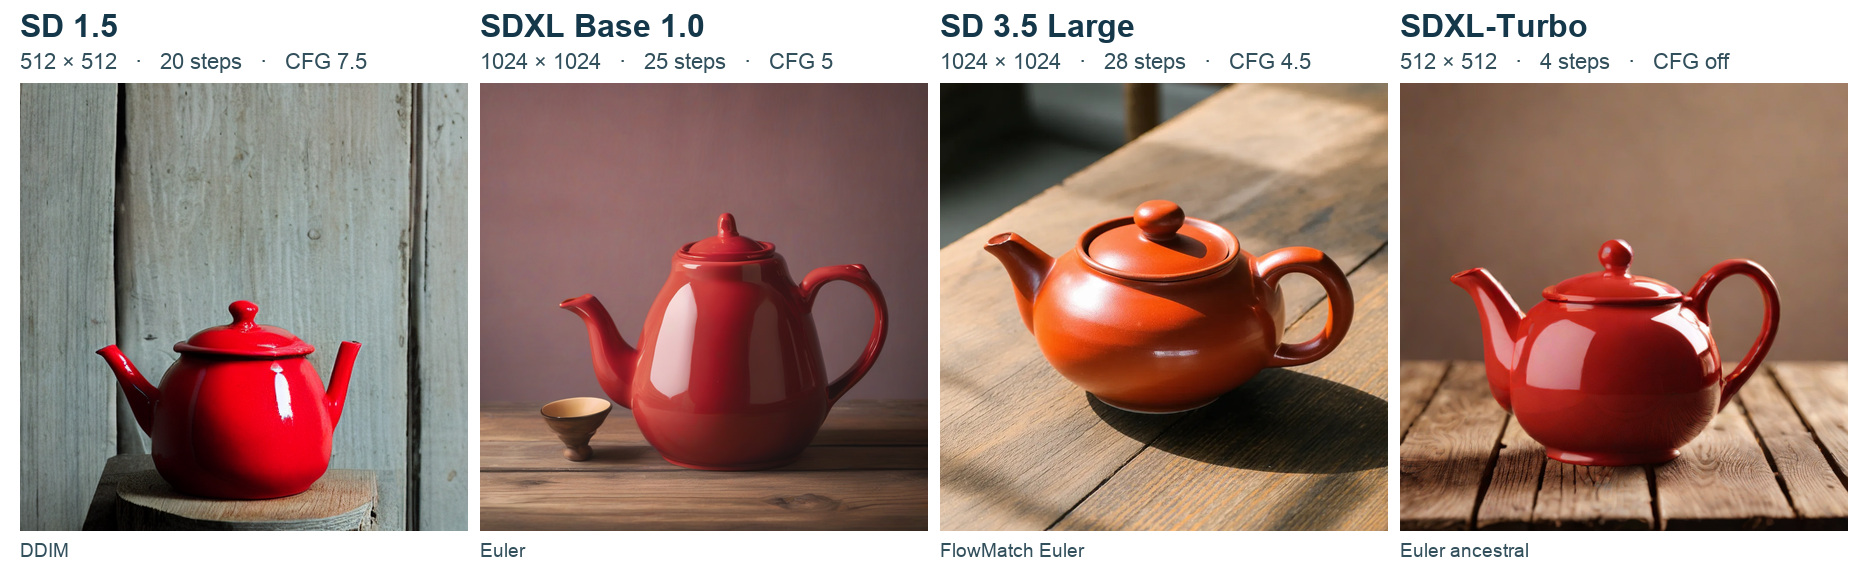

**Read across the row.** Find the spout and trace the handle before judging the glaze. In this run, SDXL Base adds a small cup that the prompt never mentions. SD 3.5 Large shows a diagonal band of sunlight and a long shadow. Compare the open loop on the Turbo handle with the short projection on the right of the SD 1.5 pot. Which details did the caption specify, and which did the models invent?

**Comparison settings.** All four runs used the same prompt, seed 42 and an empty negative prompt wherever a CFG branch was used. Each image is shown at the same display size with its full frame. The labels report the original generation settings. The models use different resolutions, latent shapes, schedulers and computation budgets; sharing a seed does not align their compositions. This is one sample per model.

SD 1.5 uses this notebook's DDIM baseline. SDXL uses the base checkpoint alone with 25 Euler steps. SD 3.5 uses the Large checkpoint from Stability AI's public demo. SDXL-Turbo uses the four-step configuration below with a fixed initial latent and scheduler-noise seed 43.

[SDXL base checkpoint](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0) · [SD 3.5 Large demo and implementation](https://huggingface.co/spaces/stabilityai/stable-diffusion-3.5-large/blob/main/app.py) · [SDXL-Turbo checkpoint](https://huggingface.co/stabilityai/sdxl-turbo)

## Why run diffusion in a latent space?
For a $512 \times 512$ RGB photograph, pixel diffusion tracks $3 \times 512 \times 512$ numbers. The SD 1.5 autoencoder maps it to a grid of $4 \times 64 \times 64$ numbers. This gives 64 times fewer spatial positions and 48 times fewer scalar coordinates. The U-Net revisits this smaller grid at every step. The actual speedup depends on the network and hardware.

**Question.** If the encoder discards a tiny inscription on the teapot, how could we discover that before running diffusion? Encode and decode the reference photo, then inspect the inscription. A generator can invent plausible lettering even when the original letters are lost.

[SD 1.5 model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)

### Learning the latent space

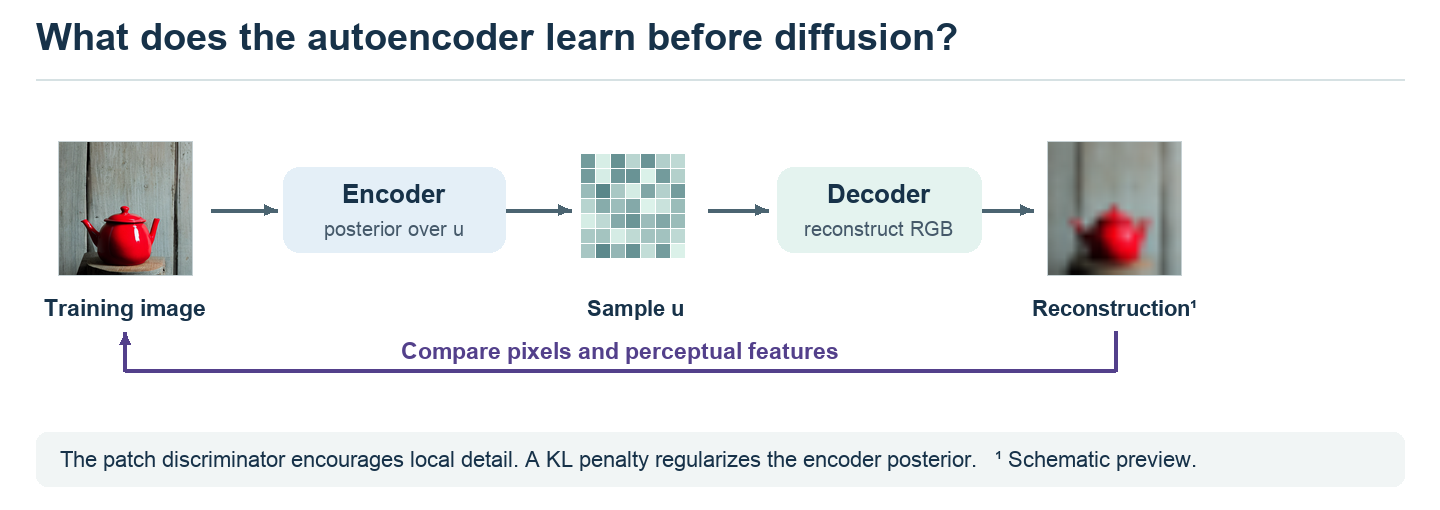

During first-stage training, the encoder samples $u\sim q_\phi(u|x)$ and the decoder produces $\hat x=D_\psi(u)$. Pixel and perceptual distances penalize lost structure; a patch discriminator encourages realistic local texture. A KL term penalizes departure of $q_\phi(u|x)$ from the Gaussian prior. Update the encoder and decoder with these signals, and train the discriminator on real versus reconstructed patches. Freeze the autoencoder when training the diffusion denoiser.

**Scale.** The SDXL paper reports a VAE training batch of 256 versus 9 for the earlier autoencoder. Its reconstruction comparison measures fidelity on held-out images. The publication does not specify how many distinct images trained each VAE.

[Rombach et al., §3.1](https://arxiv.org/abs/2112.10752) · [SDXL, §2.4](https://arxiv.org/html/2307.01952)

## Follow one training pair

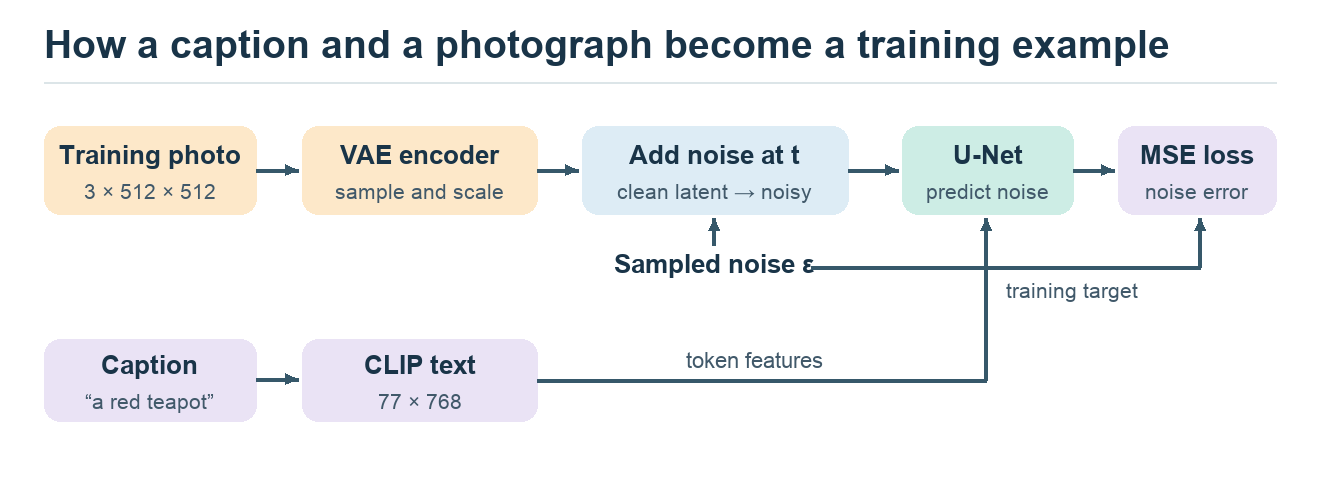

Start with the photograph. The frozen VAE encoder supplies a latent sample, which we scale and corrupt at a randomly chosen time $t$. Follow the caption through frozen CLIP to the U-Net. The U-Net sees the corrupted latent, $t$ and the text features. Follow the sampled noise a second time: the same draw supplies the target for the loss.

[Rombach et al., Fig. 3](https://ommer-lab.com/research/latent-diffusion-models/) · [Jay Alammar, The Illustrated Stable Diffusion](https://jalammar.github.io/illustrated-stable-diffusion/)

### Read the metadata before sampling a training example

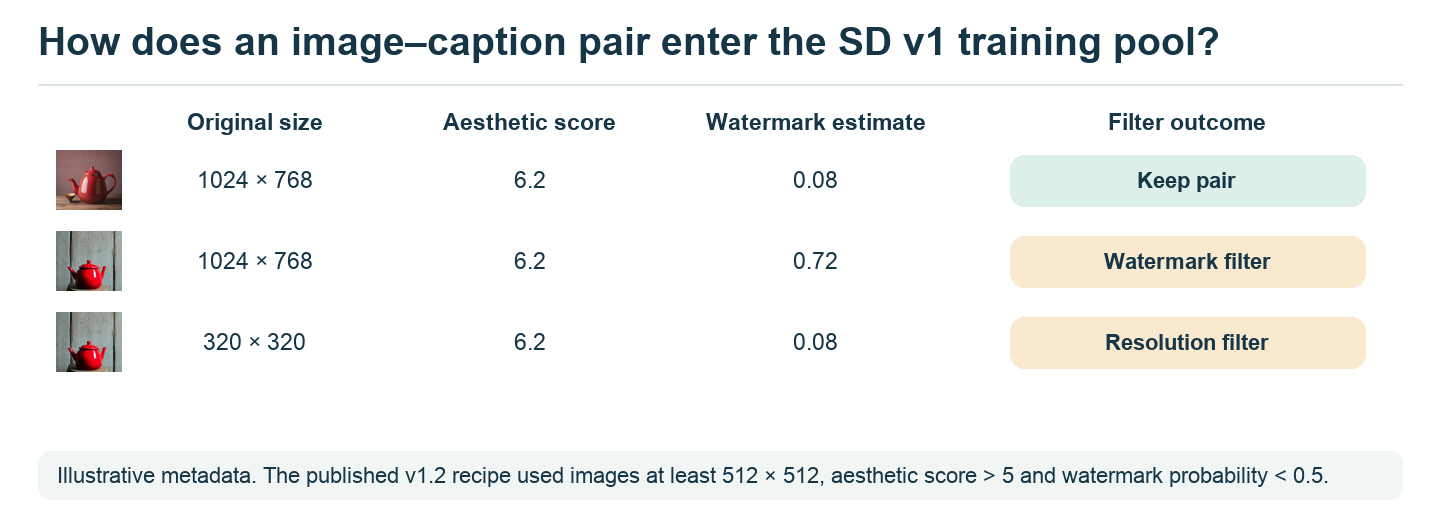

SD 1.5 continued from v1.2. The table uses the **documented v1.2 filters** for a worked example: the first two records have the same size and aesthetic score, but only the first passes the watermark filter. The teapot images and their scores in this diagram are illustrative. For v1.5, the card identifies the LAION-Aesthetics v2 5+ subset and 595k fine-tuning updates. The distinct-pair total used by that checkpoint is unspecified. [SD v1 model card, training stages](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) · [LAION dataset pools](https://laion.ai/blog/laion-aesthetics/)

### What gets trained?
| Stage | Inputs | Prediction or reconstruction | Learning signal |
|---|---|---|---|
| Autoencoder | Real image $x$ | $D(u)$, where $u$ is sampled from the encoder posterior | Pixel/perceptual reconstruction and a patch discriminator encourage fidelity. KL regularizes the posterior. |
| Latent diffusion | Noisy latent $z_t$, time $t$, caption features $h$ | U-Net output with the shape of $z_t$ | Squared error against the noise used to build $z_t$. The pretrained VAE and CLIP text encoder are frozen. |

For SD 1.5, write $z_0=k u$ with $k$ the checkpoint's VAE scaling factor. For each image-caption pair, sample $t$ and $\epsilon\sim\mathcal N(0,I)$ and form

$$z_t=\sqrt{\bar\alpha_t}\,z_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad
\mathcal L=\mathbb E\big[\|\epsilon-\epsilon_\theta(z_t,t,h)\|_2^2\big].$$

The sampled noise supplies the target. At generation time the trained network estimates it from the current latent. SD 1.5 dropped text conditioning on 10% of examples during its final training stage, enabling both CFG predictions from one model.

[Rombach et al., §3](https://arxiv.org/abs/2112.10752) · [SD 1.5 training details](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)

### SD 1.5 · count the pairs and updates separately

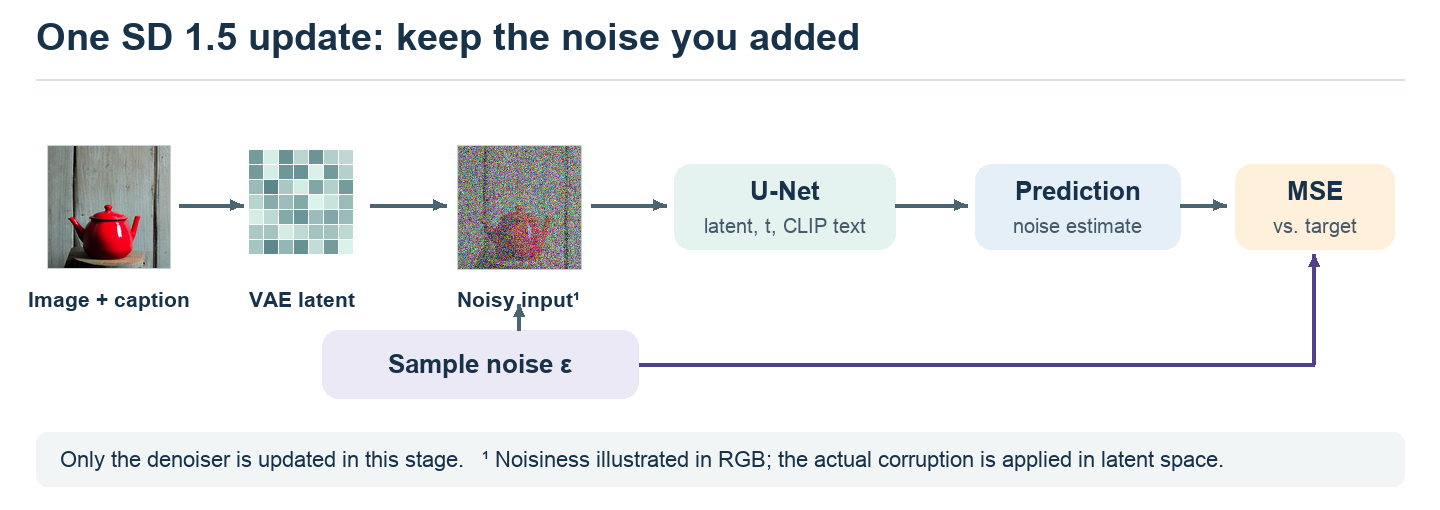

The SD 1.5 checkpoint starts from v1.2. Its last stage used **595,000 optimizer updates at 512²**, dropping the caption on 10% of examples. LAION reports **600M image–text pairs** above the aesthetic threshold of 5 in its published V2 collection. The checkpoint recipe applies additional resolution and watermark filtering. The exact number of distinct pairs seen by v1.5 is unspecified.

**Read the fork.** Following one arrow from $\epsilon$ builds the input. Following the other supplies the target. If one latent component received noise $0.7$ and the network estimated $0.4$, its contribution to the squared error is $(0.7-0.4)^2=0.09$. The gradient updates the U-Net.

[SD 1.5 model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) · [LAION-Aesthetics collection sizes](https://laion.ai/blog/laion-aesthetics/) · [CompVis filtering recipe](https://github.com/CompVis/stable-diffusion#stable-diffusion-v1)

### A caption can disappear while the target stays the same

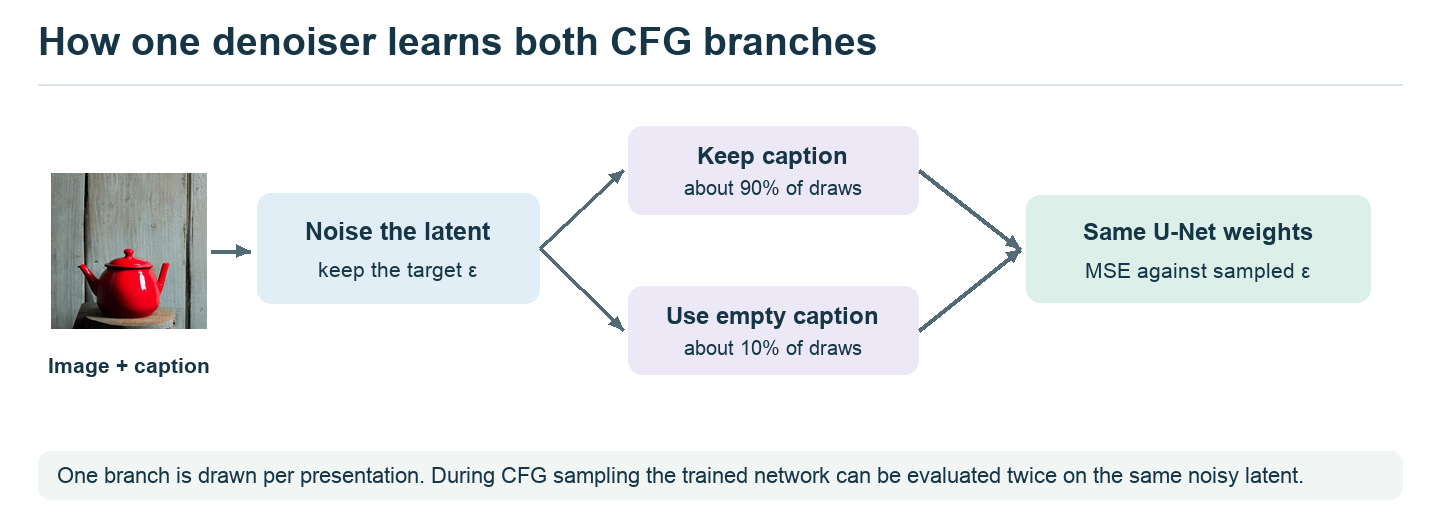

During the final SD 1.5 training stage, the caption is dropped with probability 0.1. On either draw, the target is the noise used to corrupt that example. Both branches update the same parameters. **Question:** If you dropped the image as well as the caption, which part of this training example would you lose? [SD 1.5 training recipe](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)

### How does text conditioning get learned?

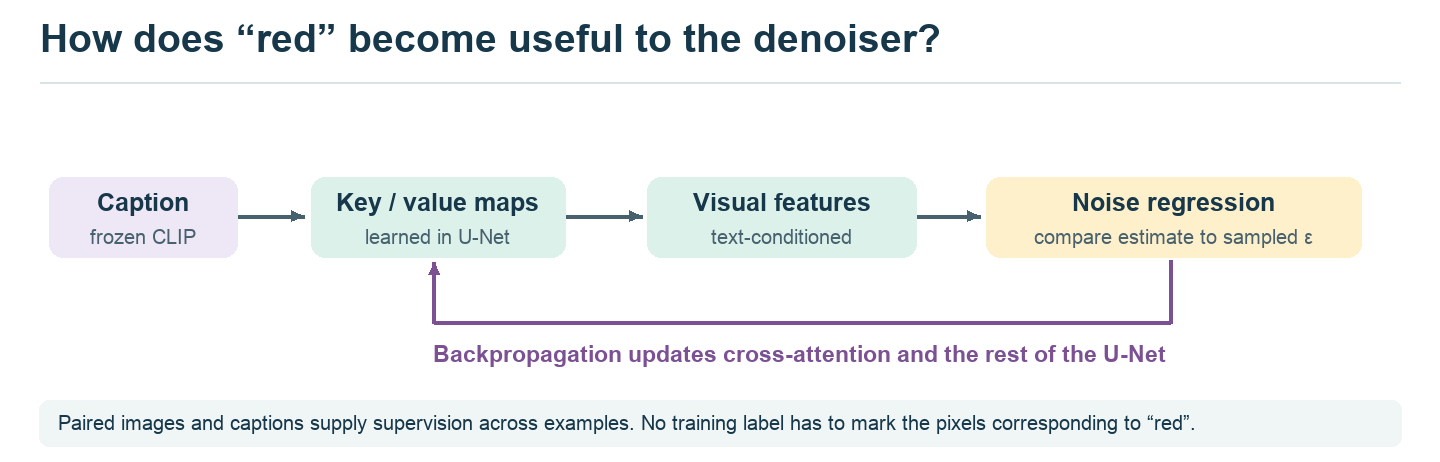

Keep the training photo and its sampled noise fixed. Its caption changes the hidden features used to predict that noise. If the prediction is inaccurate, the gradient runs back through the noise head, the visual blocks, the attention output and its query/key/value projections. The optimizer adjusts those U-Net parameters. A frozen CLIP encoder can therefore supply a useful language space while the U-Net learns how to read it. Across many pairs, color and material descriptions can help distinguish plausible clean images compatible with a noisy latent. [LDM, §3.3](https://arxiv.org/abs/2112.10752)

### Load the checkpoint
CLIP encodes the caption, the U-Net predicts noise, DDIM updates the latent and the VAE decodes it. We load the same frozen weights for every run. DDIM with $\eta=0$ makes comparisons reproducible from the same initial latent on the same device.

In [ ]:
%pip -q install diffusers==0.35.2 transformers==4.55.4 accelerate==1.10.1

In [1]:
import torch
from PIL import Image, ImageDraw
from IPython.display import display
from huggingface_hub import snapshot_download
from diffusers import AutoencoderKL, DDIMScheduler, UNet2DConditionModel
from transformers import CLIPTextModel, CLIPTokenizer
from pathlib import Path

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
dtype = torch.float32 if device == "cpu" else torch.float16
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
root = Path(snapshot_download(
    model_id, revision="451f4fe16113bff5a5d2269ed5ad43b0592e9a14",
    allow_patterns=["tokenizer/*", "text_encoder/config.json", "text_encoder/model.fp16.safetensors",
                    "scheduler/scheduler_config.json", "vae/config.json", "unet/config.json",
                    "vae/*.fp16.safetensors", "unet/*.fp16.safetensors"],
))
weights = dict(variant="fp16", torch_dtype=dtype, use_safetensors=True)
tokenizer = CLIPTokenizer.from_pretrained(root / "tokenizer")
text_encoder = CLIPTextModel.from_pretrained(root / "text_encoder", **weights).to(device).eval()
unet = UNet2DConditionModel.from_pretrained(root / "unet", **weights).to(device).eval()
vae = AutoencoderKL.from_pretrained(root / "vae", **weights).to(device).eval()
scheduler = DDIMScheduler.from_pretrained(root / "scheduler")
assert scheduler.config.prediction_type == "epsilon" and not scheduler.config.clip_sample
print(f"{device} | latent channels: {unet.config.in_channels} | VAE scale: {vae.config.scaling_factor}")

mps | latent channels: 4 | VAE scale: 0.18215


## Inside one U-Net call

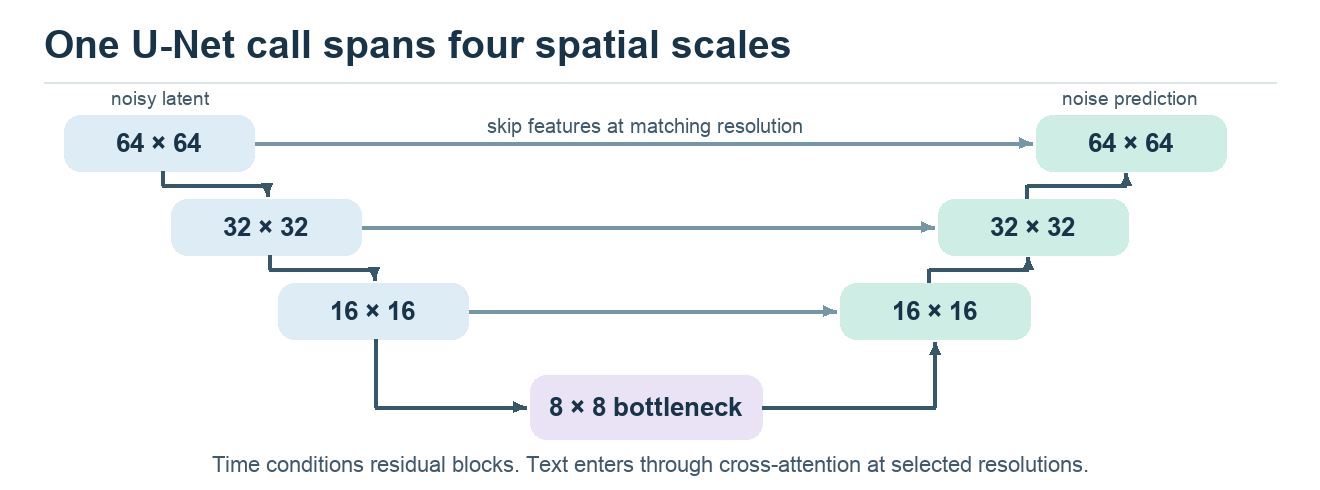

Trace a feature from the upper left down to the bottleneck. Coarser resolutions combine information across distant locations, such as the handle and the spout. Trace the skip connection across the U: the up block receives spatially aligned features from the down path. This helps it recover local detail. A time embedding tells residual blocks how noisy the input is.

The down/up paths run **inside one denoising evaluation**. The next sampler step calls the same U-Net again at a different time.

[SD 1.5 U-Net configuration](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5/blob/main/unet/config.json)

### How does “red ceramic” reach a position?

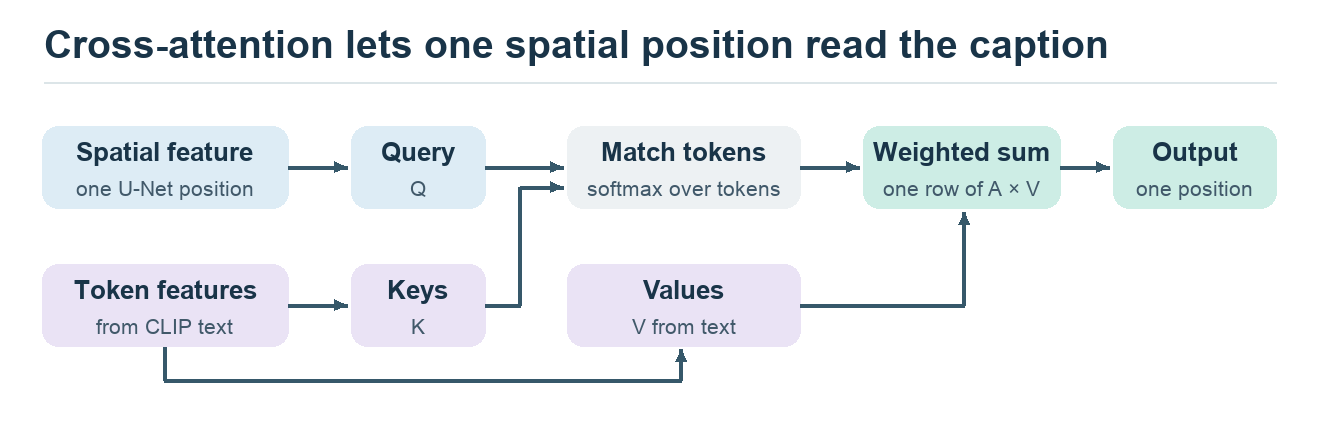

Flatten an intermediate feature map into $N=H W$ spatial vectors $F$. Encode the caption into $L=77$ token positions (including padding), with 768 features per position for SD 1.5. For one attention head,

$$Q=F W_Q,\quad K=h W_K,\quad V=h W_V,\qquad
A=\operatorname{softmax}_{\rm tokens}\!\left(\frac{QK^\top}{\sqrt d}\right),\qquad O=A V.$$

Read one row of $A\in\mathbb R^{N\times L}$: for one spatial position, its weights across text tokens sum to one. A position on the teapot can use color and material cues from multiple tokens. In self-attention the keys and values also come from spatial features. In cross-attention they come from the text sequence. CLIP's image encoder is unnecessary in this sampling path.

[Rombach et al., §3.3](https://arxiv.org/abs/2112.10752)

### Compute one head by hand

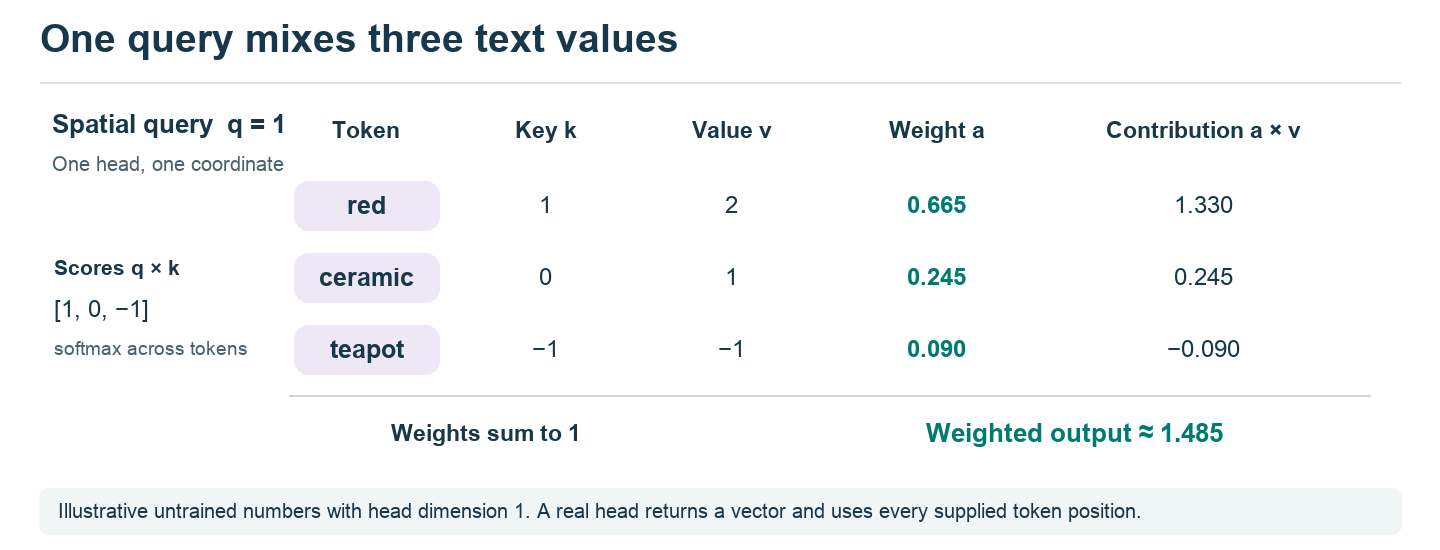

Pick one spatial location and one head. Its query $q_i$ represents the current **visual** features there. Each contextual text vector $h_j$ is projected twice: $k_j$ enters the matching score, and $v_j$ supplies the information sent back. The same trained matrices are reused at every position in this layer.

In the toy example $d=1$. The scaled dot products are $[1,0,-1]$. Exponentiating and dividing by $e^1+e^0+e^{-1}$ gives weights $[0.665,0.245,0.090]$. Multiply those by the **values** $[2,1,-1]$ and sum. If another image position had $q_i=0$, its three scores would tie, yielding equal weights and output $(2+1-1)/3$. Both positions read the same words and can retrieve different features.

For a real SD 1.5 head with a 32 × 32 feature map, there are **1,024 queries**, each with a row of **77 token weights**. Taking a row answers “which tokens does this position read?” Taking the column for *teapot* and reshaping the 1,024 entries gives a spatial map like the one below. Softmax normalizes each row across tokens. [Diffusers attention implementation](https://github.com/huggingface/diffusers/blob/v0.35.2/src/diffusers/models/attention_processor.py)

### How does the retrieved text enter the image stream?

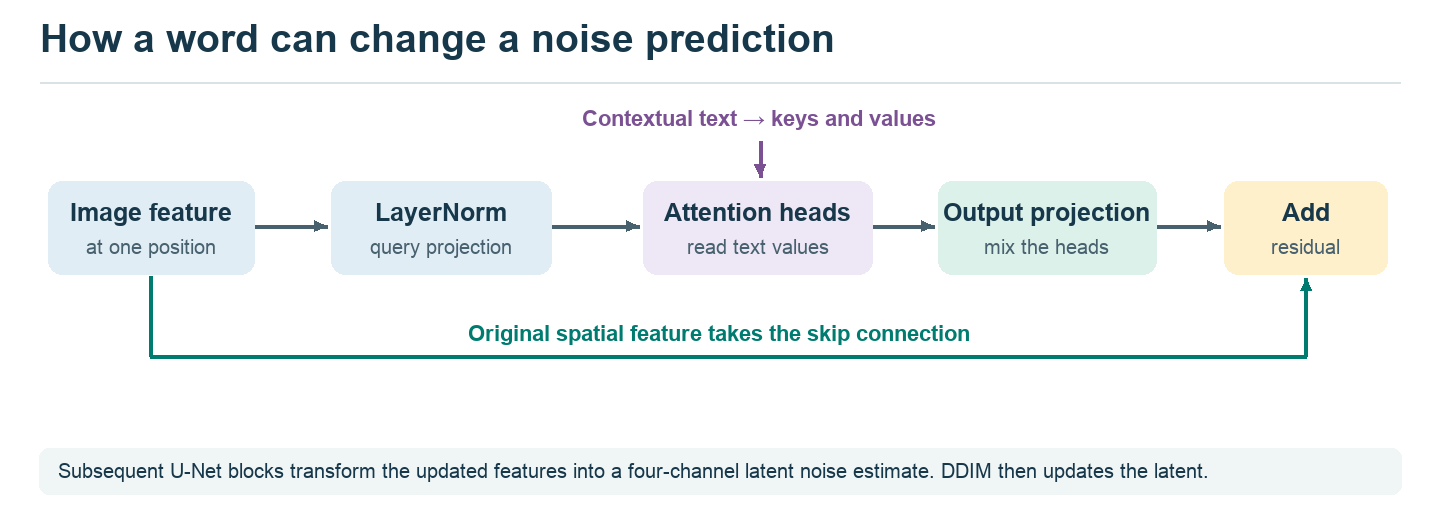

In the SD 1.5 transformer block, self-attention has already mixed information between spatial positions. Call the resulting feature $f_i$. Cross-attention uses a normalized version of it for the query. Each head returns a weighted sum of text values; concatenate the heads, project them back to the spatial feature width, then add the result:
$$f'_i=f_i+W_O\,[o_i^{(1)};\ldots;o_i^{(H)}]+b_O.$$
The feed-forward layer and later U-Net blocks process $f'_i$. Only at the end does the noise head emit $\epsilon_\theta(z_t,t,c)$, which the scheduler uses to compute the next latent. The attention weight for *red* is a mixing coefficient. Color in RGB emerges after subsequent denoising and the VAE decode.

In the code, follow **`context = encode(caption)` → `encoder_hidden_states=context` → `.sample.chunk(2)` → `scheduler.step(...)`**. The text-conditioned prediction already exists before CFG combines it with the empty-caption prediction. [BasicTransformerBlock in Diffusers](https://github.com/huggingface/diffusers/blob/v0.35.2/src/diffusers/models/attention.py)

### Where did the text features learn their meaning?

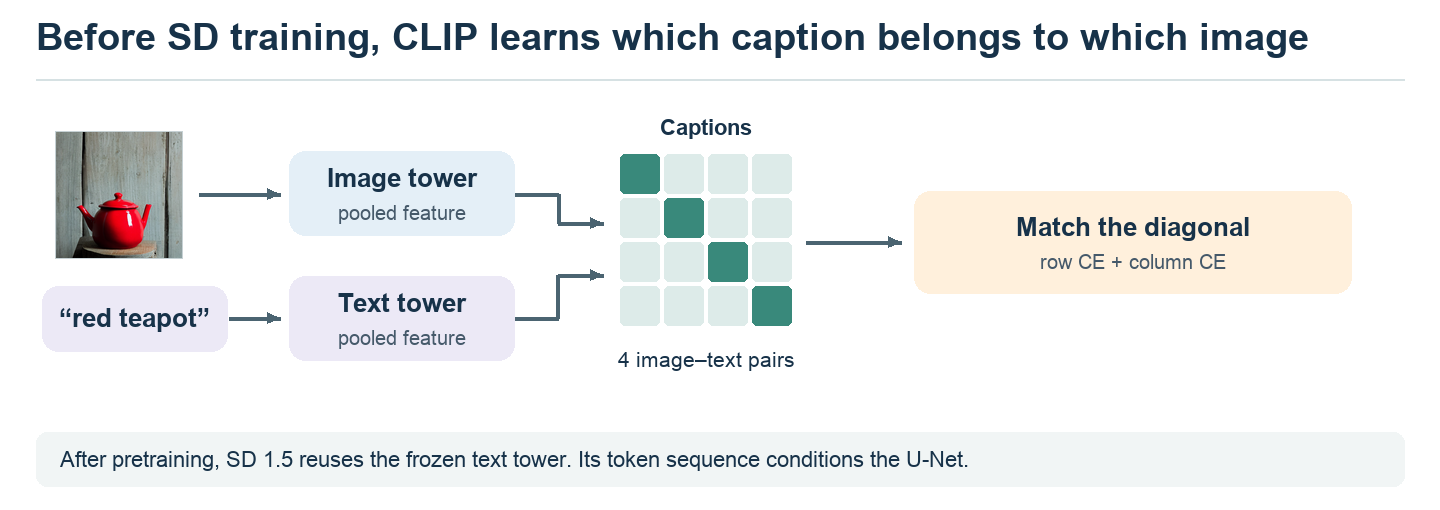

For a batch of $B$ image–caption pairs, let $S_{ij}$ be the temperature-scaled cosine similarity of image $i$ and caption $j$. The correct caption for image $i$ is column $i$. Each column gives the reverse retrieval task. CLIP averages cross-entropy in the two directions:
$$\mathcal L_{\rm CLIP}=\tfrac12\big[\mathrm{CE}_{\rm rows}(S,\mathrm{diag})+\mathrm{CE}_{\rm cols}(S,\mathrm{diag})\big].$$
The original OpenAI CLIP study assembled **400M image–text pairs**. This figure belongs to CLIP pretraining. Once that stage is over, SD 1.5 reuses the frozen text tower's per-token hidden states; its own denoising batches train the U-Net.

[Radford et al., §§2.2–2.3 and Fig. 3](https://arxiv.org/abs/2103.00020) · [SD 1.5 model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)

### Inspect the two conditioning tensors
Our prompt asks for a red teapot on a wooden table. Predict the shape of the conditioning before running the cell. The first batch entry encodes the empty caption and the second encodes the requested scene. Each spatial location in a cross-attention block can read these token features.

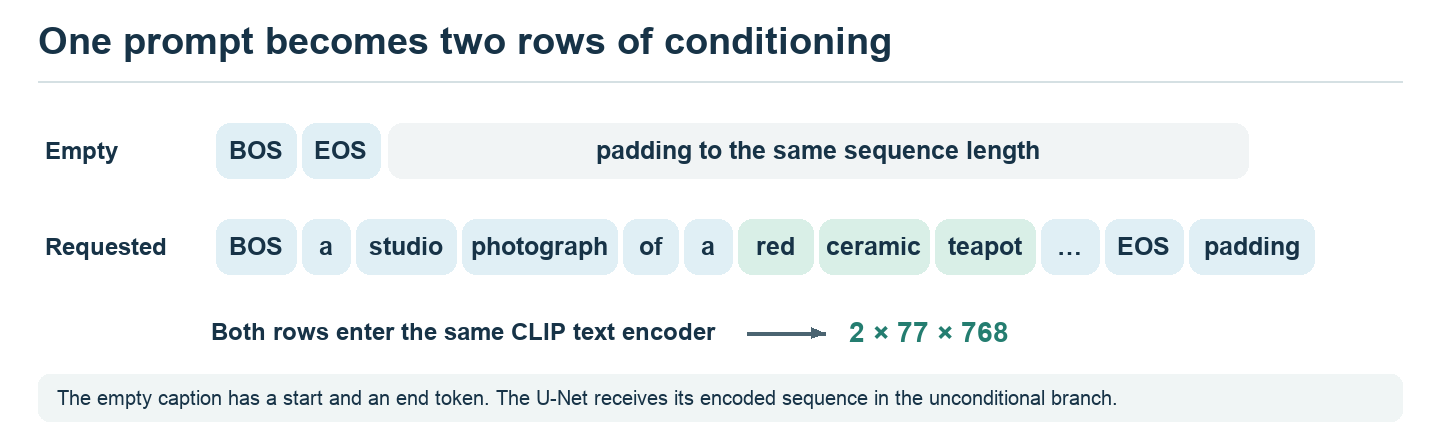

BOS and EOS mark the beginning and end of text. The ellipsis abbreviates the remaining words of the prompt. Each of the 77 positions has 768 features after encoding.

### The ID of “teapot” stays fixed. Does its vector change?

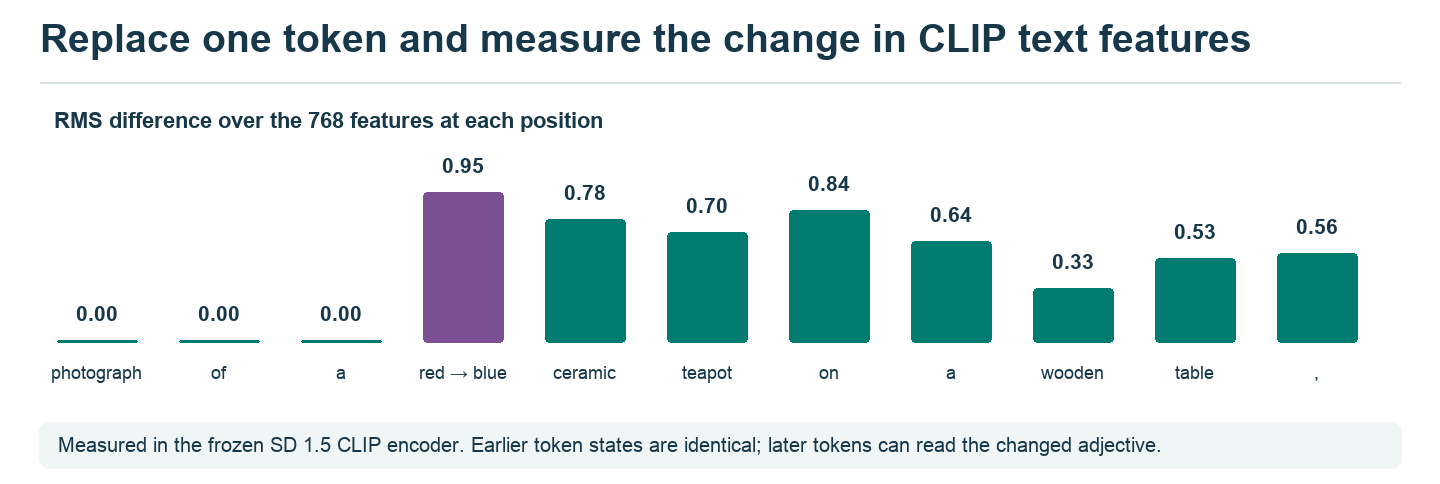

A token ID selects a learned embedding. CLIP adds a position embedding and runs its text transformer to produce a contextual vector for each position. Its causal attention allows a position to read words to its left. In *red ceramic teapot*, the vector at *teapot* can therefore depend on *red*.

For this measurement we changed exactly one token to *blue*, kept the same sequence length, and compared the last hidden states in float32 after the SD 1.5 text encoder. Each bar is $\sqrt{\mathrm{mean}_k (h^{\rm red}_{jk}-h^{\rm blue}_{jk})^2}$ for one token position $j$, across its 768 features. The prefix before the adjective is identical. The RMS change at *teapot* is about **0.70** in this run. The chart shows a window of the full prompt. [CLIP text implementation](https://github.com/huggingface/transformers/blob/v4.55.4/src/transformers/models/clip/modeling_clip.py)

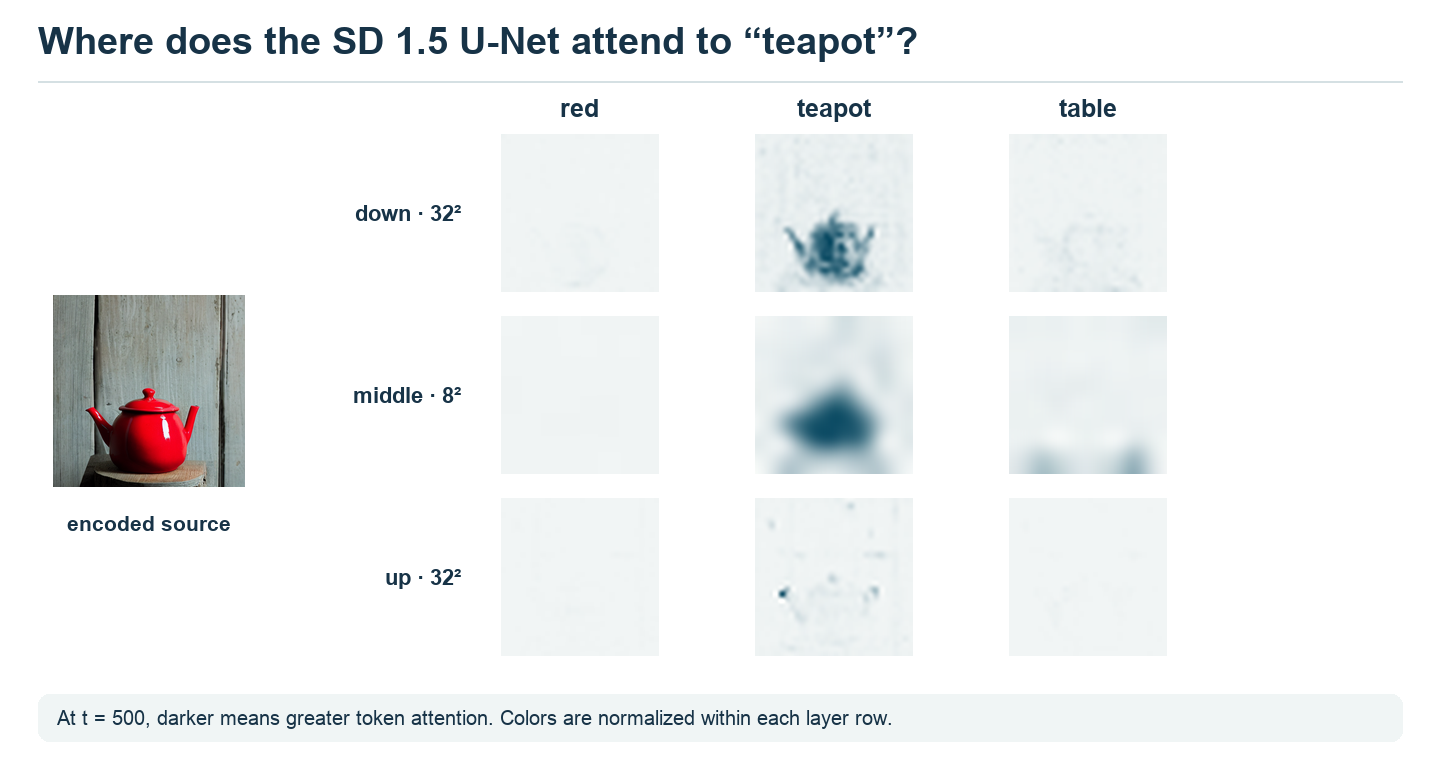

**Read down the middle column.** In this run the down block assigns attention to “teapot” near its outline. The 8 × 8 middle block localizes it more coarsely. These are measurements from the conditional branch at training timestep 500, using the encoded generated photo with added noise (seed 44). We recompute softmax over the text keys from the first cross-attention module of down block 1, the middle block and up block 2 (zero-based), then average over heads. The color scale is shared across the three words within each row. These weights measure token attention in those layers; establishing causal influence would require a separate intervention.

In [2]:
prompt = "a studio photograph of a red ceramic teapot on a wooden table, soft daylight"
seed = 42
@torch.inference_mode()
def encode(caption):
    ids = tokenizer(["", caption], padding="max_length", max_length=tokenizer.model_max_length,
                    truncation=True, return_tensors="pt").input_ids
    return text_encoder(ids.to(device)).last_hidden_state

def fixed_noise(seed, shape):
    generator = torch.Generator(device="cpu").manual_seed(seed)
    return torch.randn(shape, generator=generator).to(device=device, dtype=dtype)

initial = fixed_noise(seed, (1, 4, 64, 64))
print("Text features:", tuple(encode(prompt).shape), "| initial latent:", tuple(initial.shape))

Text features: (2, 77, 768) | initial latent: (1, 4, 64, 64)


## From one DDIM step to an image

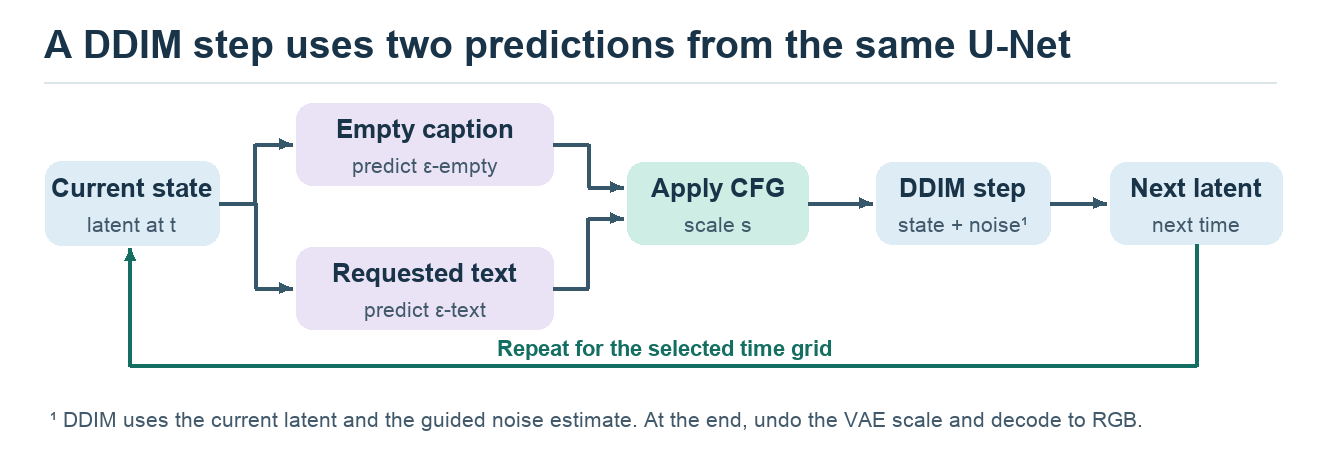


1. Encode the empty caption and the requested caption once. Draw $z_T\sim\mathcal N(0,I)$.
2. At time $t$, pass the same $z_t$ to both branches of the U-Net. Combine their predictions with $\hat\epsilon_s=\epsilon_\varnothing+s(\epsilon_c-\epsilon_\varnothing)$.
3. Pass $z_t$, $t$ and $\hat\epsilon_s$ to the scheduler. Its update gives the next latent on the chosen time grid. Repeat until the end.
4. Undo the scale and decode $D(z_0/k)$ to RGB.

**Connection to Imagen.** Pixel values have a display range. SD's four latent channels are learned coordinates with their own scale. Applying Imagen's pixel threshold directly to this grid would alter the denoiser's state. Below, the DDIM scheduler uses the checkpoint configuration with latent clipping disabled.

[Diffusers pipeline walkthrough](https://huggingface.co/docs/diffusers/using-diffusers/write_own_pipeline)

In the loop below, compare `update.prev_sample` (the state passed to the next step) with `update.pred_original_sample` (the clean-latent estimate decoded for each preview).

In [3]:
@torch.inference_mode()
def decode(z):
    rgb = vae.decode(z / vae.config.scaling_factor).sample
    pixels = ((rgb[0].float().clamp(-1, 1) + 1) * 127.5).round().byte()
    return Image.fromarray(pixels.permute(1, 2, 0).cpu().numpy())

@torch.inference_mode()
def denoise(start, caption, scale, timesteps, capture=()):
    context = encode(caption)
    z = start.clone()
    snapshots = []
    for step, t in enumerate(timesteps, start=1):
        inputs = scheduler.scale_model_input(torch.cat([z, z]), t)
        eps_empty, eps_text = unet(inputs, t, encoder_hidden_states=context).sample.chunk(2)
        eps = eps_empty + scale * (eps_text - eps_empty)
        update = scheduler.step(eps, t, z, eta=0)
        if step in capture:
            snapshots.append((f"step {step} / {len(timesteps)}", decode(update.pred_original_sample)))
        z = update.prev_sample
    return decode(z), snapshots

def generate(caption, scale=7.5, steps=20, capture=()):
    scheduler.set_timesteps(steps, device=device)
    return denoise(initial * scheduler.init_noise_sigma, caption, scale, scheduler.timesteps, capture)

def show_row(items):
    side = min(320, 1024 // len(items))
    row = Image.new("RGB", (side * len(items), side + 32), "white")
    draw = ImageDraw.Draw(row)
    for i, (label, image) in enumerate(items):
        row.paste(image.resize((side, side), Image.Resampling.LANCZOS), (i * side, 30))
        draw.text((i * side + 8, 8), label, fill="#183047")
    display(row)

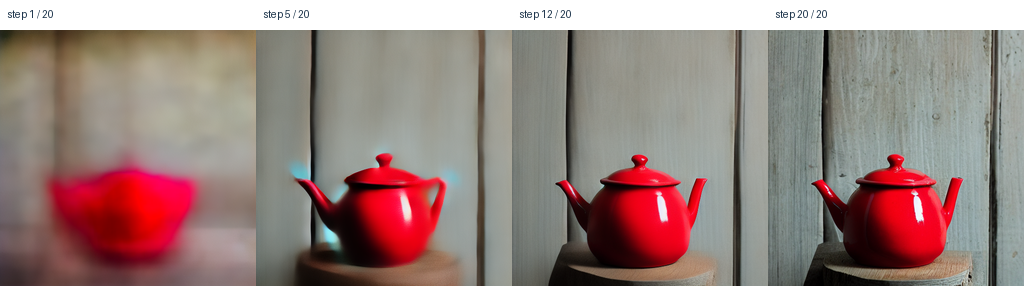

In [4]:
baseline, snapshots = generate(prompt, capture=(1, 5, 12, 20))
show_row(snapshots)

**Read the strip from left to right.** Each panel shows the current guess of the finished image. Find the earliest panel where you can identify the object, then track its handle, surface and shadow. The full-resolution final sample is stored in `baseline`.

In the saved run, a blurred red region is visible at step 1. The lid and spout can already be distinguished at step 5. By step 20 the grain of the wood behind the pot is visible.

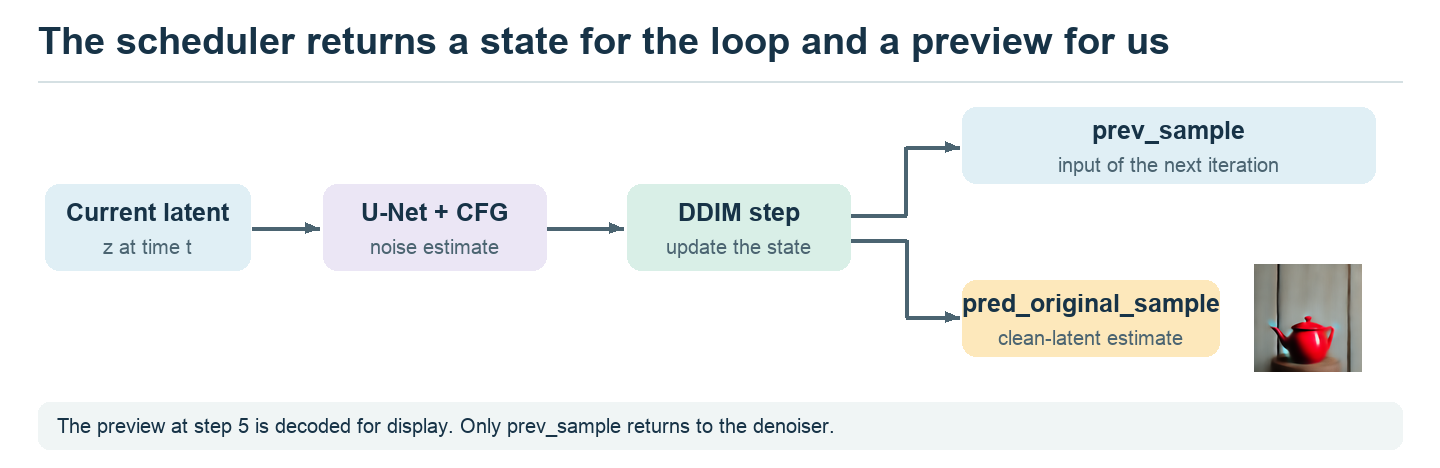

Follow the upper arrow to read the sampler loop. Follow the lower arrow to read the four previews above. The step-5 thumbnail comes from the saved trajectory.

### Controlled prompt edit · red versus blue

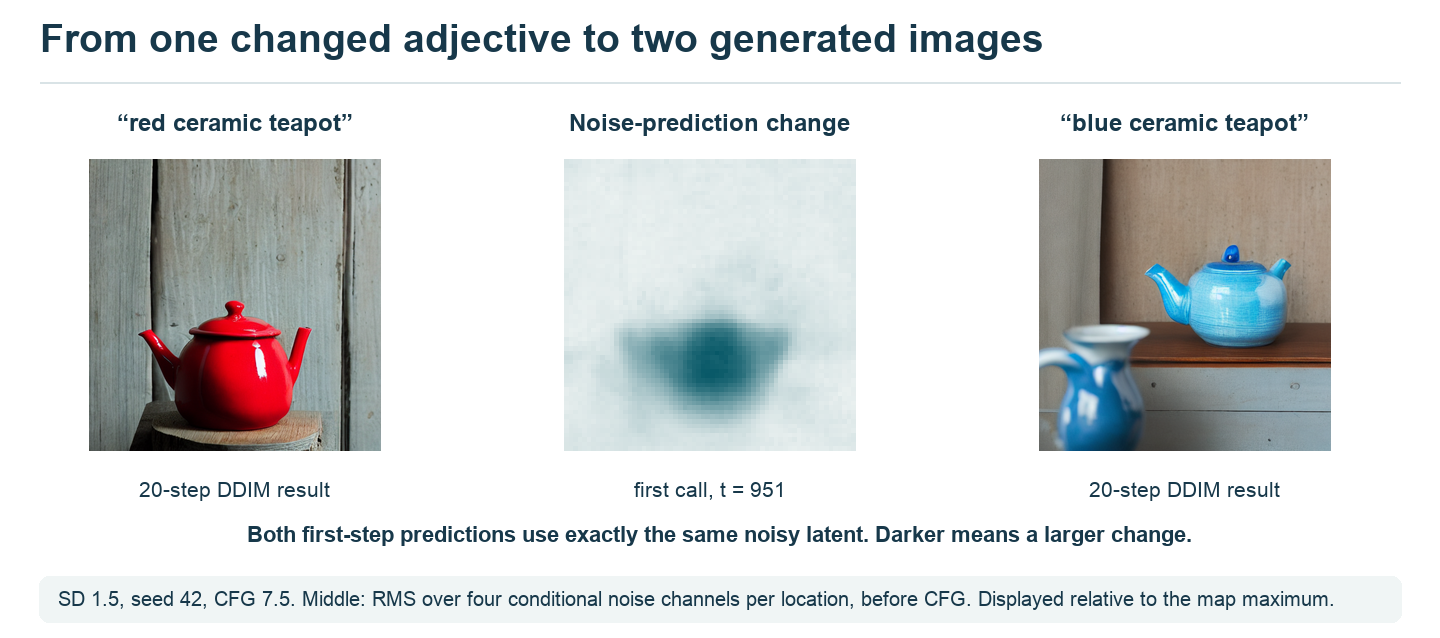

At the first scheduler time, compare $\epsilon_\theta(z_t,t,c_{\rm red})$ and $\epsilon_\theta(z_t,t,c_{\rm blue})$ **before CFG**. For each spatial location, the center panel shows the RMS difference over its four latent channels. Both calls receive exactly the same $z_t$ and $t$; only the encoded caption differs. This map measures an output change across the entire U-Net. The earlier token-attention maps measured weights inside individual layers.

Now run both trajectories to completion with the same initial noise, 20 DDIM steps and guidance 7.5. The changed caption affects color and composition: the blue pot sits farther back, and another vessel appears in front. After the first update the two latent states can diverge, so the final image difference includes all subsequent steps. To reproduce the blue sample after the baseline cell:

```python
blue_prompt = prompt.replace("red ceramic", "blue ceramic")
blue_image, _ = generate(blue_prompt, scale=7.5, steps=20)
show_row([("red", baseline), ("blue", blue_image)])
```

## Compare guidance and step count
First keep 20 DDIM steps and vary $s$. At $s=1$ the combined prediction equals the conditional prediction. Then keep $s=7.5$ and compare 6 versus 20 steps. Both comparisons reuse exactly the same noise tensor and caption. Inspect the red glaze, the outline and the contact shadow.

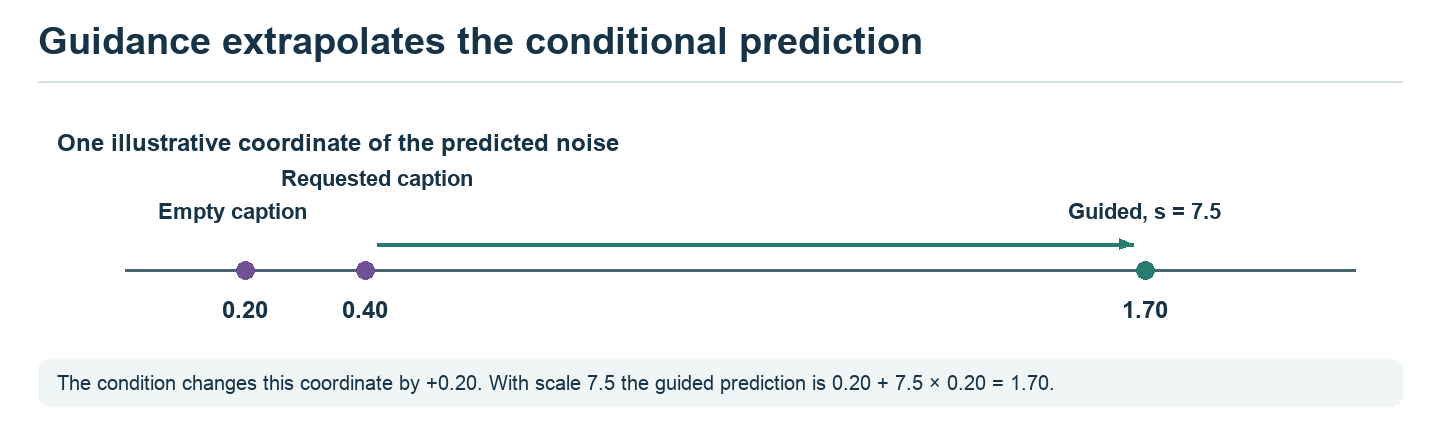

Try the arithmetic at $s=0$ and $s=1$, then locate both answers on the axis. A guided noise estimate can exceed 1; this coordinate is a predicted noise component.

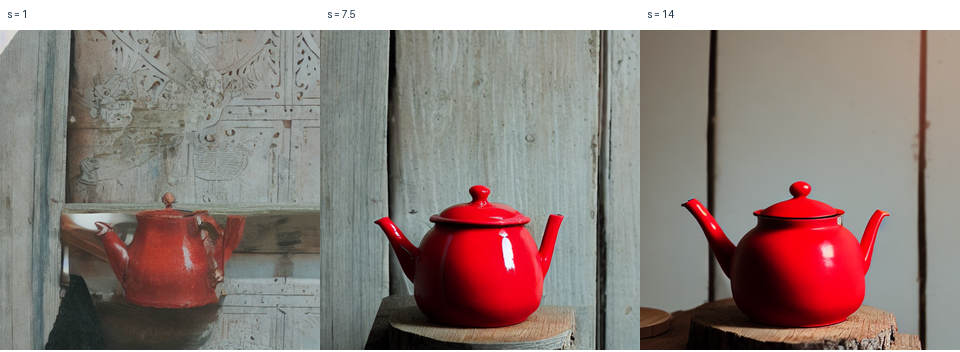

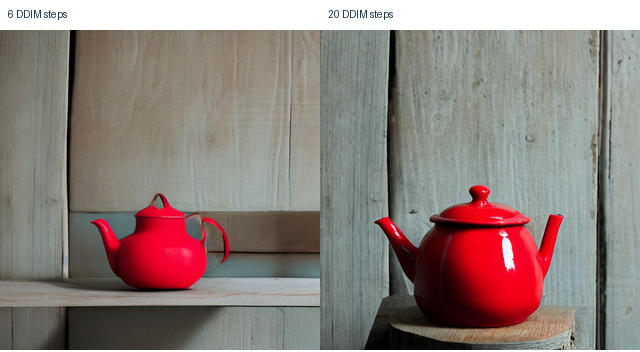

In [5]:
ordinary, _ = generate(prompt, scale=1)
strong, _ = generate(prompt, scale=14)
show_row([("s = 1", ordinary), ("s = 7.5", baseline), ("s = 14", strong)])
coarse, _ = generate(prompt, steps=6)
show_row([("6 DDIM steps", coarse), ("20 DDIM steps", baseline)])

Which setting best conveys “red ceramic”? Where can you still see texture? Check the handle and spout before judging the whole scene. To test consistency across seeds, change `seed`, recreate `initial` and rerun the trajectory and both comparisons.

In the saved comparison, the pot nearly blends into the wall at $s=1$. At $s=14$ it stands out against a smoother background. The six-step sample also places a smaller pot lower in the frame than the twenty-step sample.

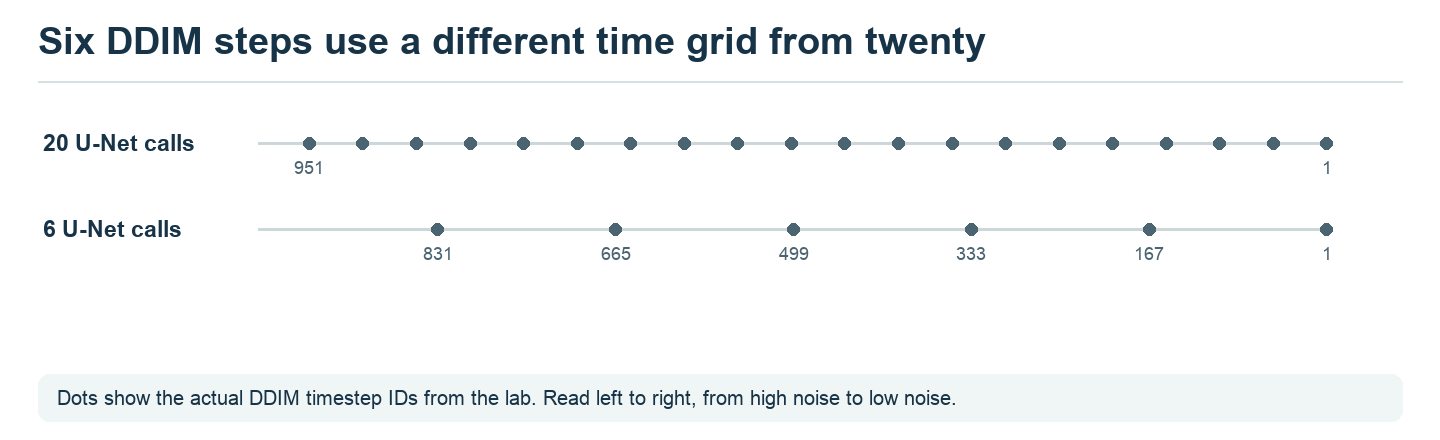

The six-step run starts at timestep 831 and the twenty-step run at 951 with this checkpoint’s scheduler settings. Both finish the reverse schedule. Keeping the initial noise tensor fixed lets us compare the effect of changing the grid.

## Edit the generated photo with img2img

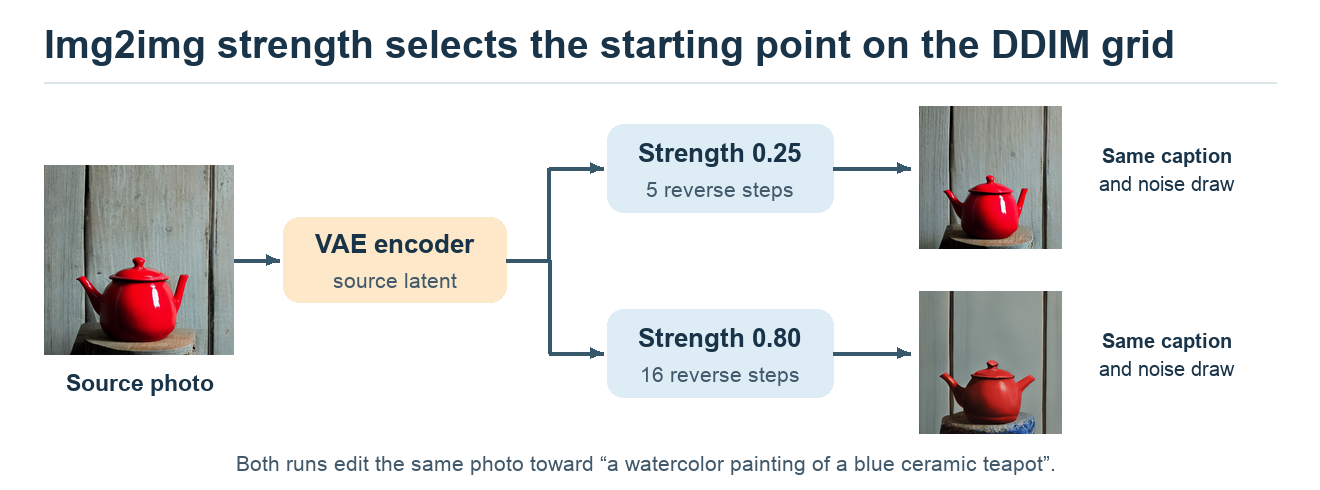

Start with a photograph we want to edit. Encode it to $z_{\rm src}$ and pick a time on the DDIM grid. Form $z_t=\sqrt{\bar\alpha_t}\,z_{\rm src}+\sqrt{1-\bar\alpha_t}\,\epsilon$. Run the remaining reverse steps with a new caption, then decode.

| Control | Where it acts | What to inspect in the lab |
|---|---|---|
| Guidance scale $s$ | Relative contribution of the caption at each denoising step | Is the teapot red? Are its texture and shadow still plausible? |
| Number of steps | Discretization of the reverse path | Does the handle meet the body? Is the spout coherent? |
| Img2img strength | Starting noise level and remaining length of the reverse path | Is the silhouette preserved when changing a photo into a watercolor? |

### Inspect the VAE reconstruction first
Encode the baseline photo, then use its posterior mode so VAE encoding is deterministic. Compare its reconstruction with the original first. Any difference here already exists before diffusion editing.

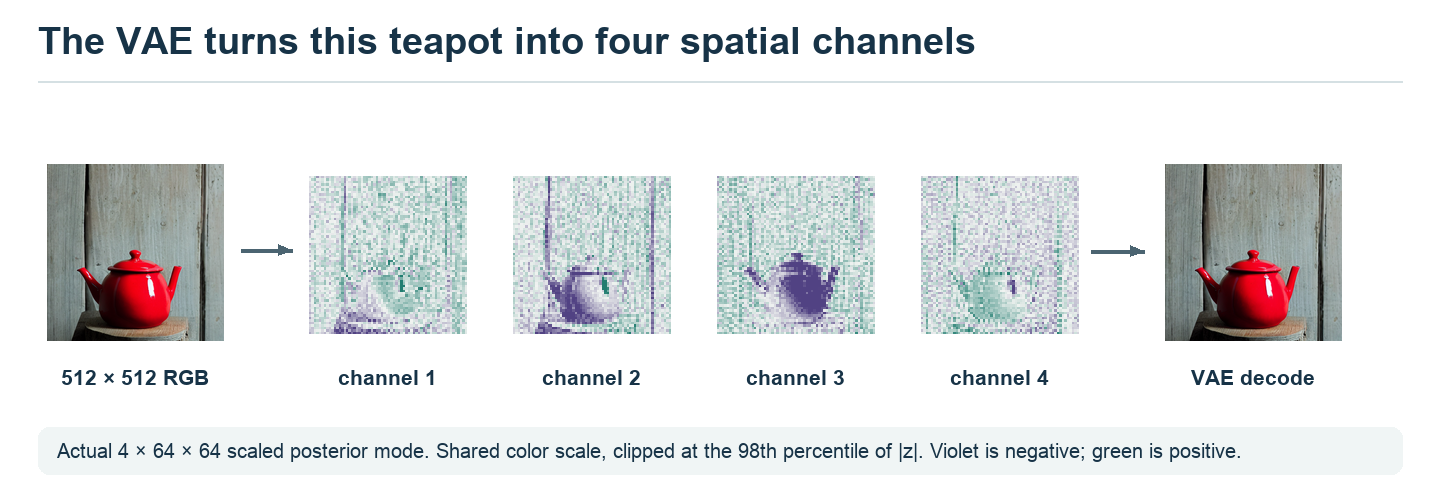

The maps show the four channels returned by the VAE posterior mode after applying the SD 1.5 scaling factor. They share one diverging color scale. The reconstructed RGB image at the right uses all four channels.

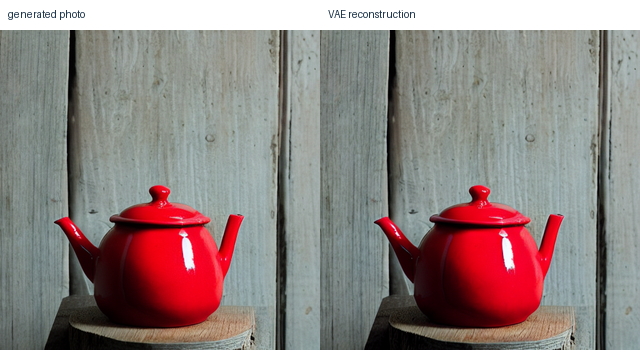

In [6]:
import numpy as np

@torch.inference_mode()
def encode_image(image):
    pixels = torch.from_numpy(np.asarray(image.convert("RGB")).copy())
    pixels = (pixels.permute(2, 0, 1).unsqueeze(0).float() / 127.5 - 1).to(device, dtype)
    return vae.encode(pixels).latent_dist.mode() * vae.config.scaling_factor

source_z = encode_image(baseline)
show_row([("generated photo", baseline), ("VAE reconstruction", decode(source_z))])

A strength of $k/N$ starts the editor with $k$ reverse updates remaining on our $N$-step grid. At the selected time add noise using $z_t=\sqrt{\bar\alpha_t}z_0+\sqrt{1-\bar\alpha_t}\epsilon$. Both edits share the same source, target caption, noise draw, schedule and CFG scale. A larger strength couples a noisier start with more reverse updates.

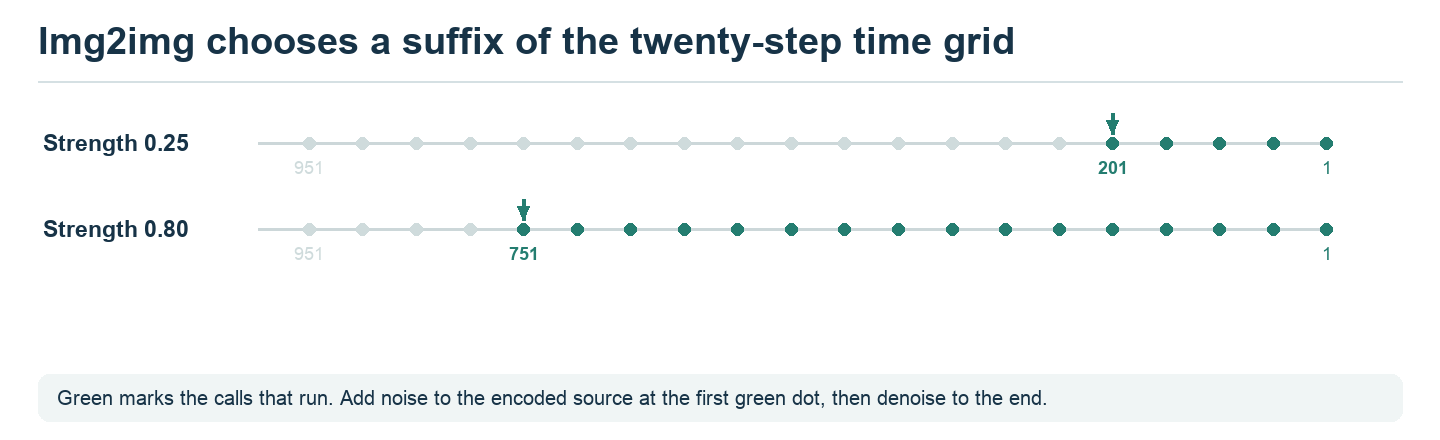

For strength 0.25 the chosen starting time is 201; for 0.80 it is 751. In both runs, the scheduler adds the same fixed noise draw to the source latent with the coefficients for that starting time.

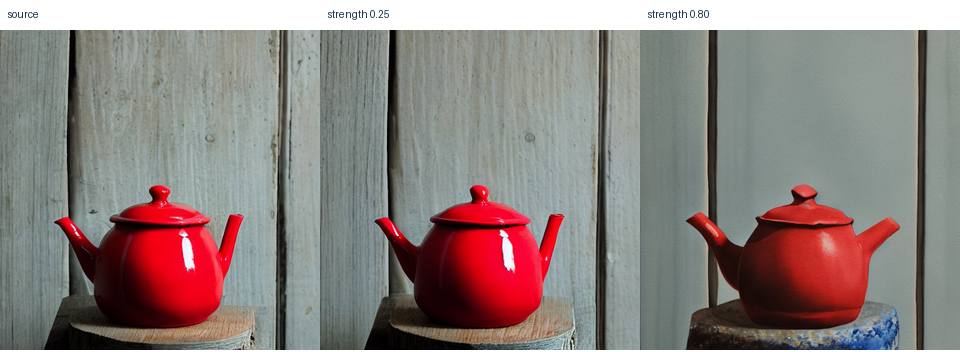

In [7]:
edit_caption = "a watercolor painting of a blue ceramic teapot on paper, loose brush strokes"
edit_noise = fixed_noise(seed + 1, source_z.shape)

def edit(strength, steps=20):
    scheduler.set_timesteps(steps, device=device)
    count = min(int(steps * strength), steps)
    if count < 1 or not 0 < strength <= 1:
        raise ValueError("Choose strength in [1 / steps, 1].")
    remaining = scheduler.timesteps[-count:]
    noisy = scheduler.add_noise(source_z, edit_noise, remaining[:1])
    result, _ = denoise(noisy, edit_caption, 7.5, remaining)
    return result

show_row([("source", baseline), ("strength 0.25", edit(0.25)), ("strength 0.80", edit(0.8))])

**Discuss.** Trace the outline of the source teapot in each edit. Which version retains its position? Which follows the requested color and medium? Explain separately what `strength` changes at initialization and what guidance changes inside every U-Net step.

In the saved run, the 0.25 edit keeps the source nearly intact. At 0.80 the spout and surface change, yet the pot stays red despite the request for blue. Try a second seed before generalizing about color control.

[SD 1.5 weights and model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) · [Diffusers walkthrough](https://huggingface.co/docs/diffusers/using-diffusers/write_own_pipeline) · [Previous YSDA playground](https://github.com/r-isachenko/2025-DGM-MIPT-YSDA-course/blob/main/seminars/seminar11/seminar11_SD.ipynb)

## SDXL base · where does each part of the prompt go?

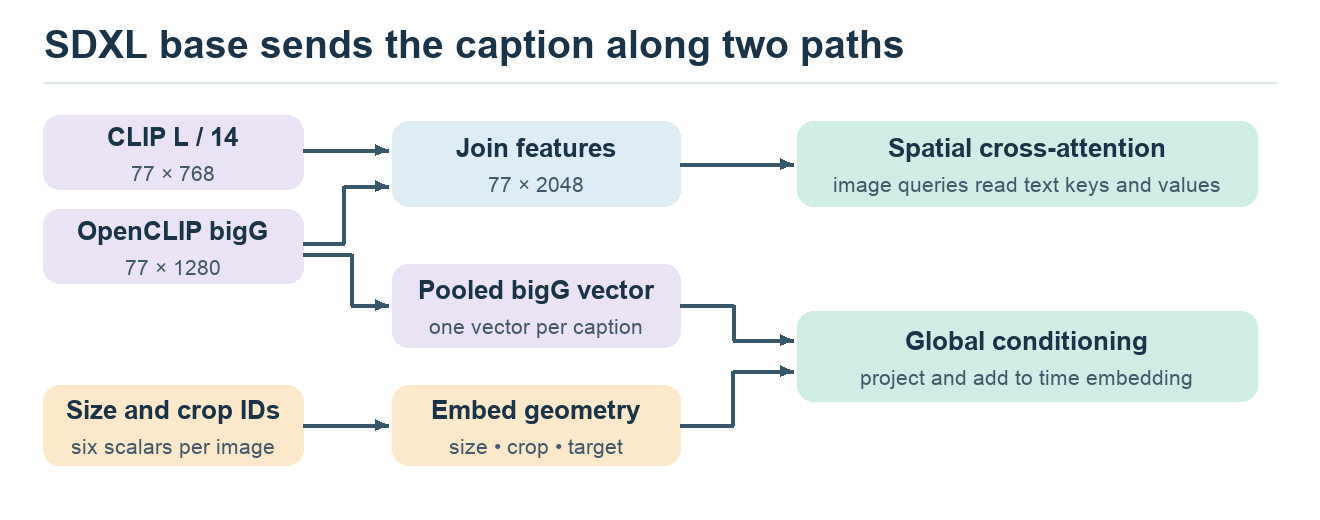

SD 1.5 used one CLIP-L text tower. SD 2.x retained the U-Net and switched to OpenCLIP ViT-H; SD-Turbo descends from that branch. XL base uses two text towers.

Read the top route for the word *red*. Both encoders tokenize the caption and return 77 position vectors. SDXL base concatenates their penultimate hidden states **along the feature dimension**. At each U-Net cross-attention layer, spatial features supply the queries; this 77 × 2048 context supplies the keys and values.

Read the lower route for *the composition as a whole*. The second encoder (bigG) also returns one pooled 1280-dimensional vector. Six numbers describe original height/width, crop top/left and target height/width. The model embeds those numbers, concatenates them with the pooled vector, then projects the result and adds it to the timestep embedding. Each denoising call reuses the text context and global condition.

**Ask the room.** If we keep the prompt fixed and change the requested crop, which of the two routes changes? The geometry part of the global vector. This is learned conditioning, so the generated composition can respond without obeying exact pixel coordinates.

[SD 2.x architecture](https://github.com/Stability-AI/stablediffusion) · [SDXL paper, §§2.1–2.2](https://arxiv.org/abs/2307.01952) · [SDXL base U-Net configuration](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0/blob/main/unet/config.json)

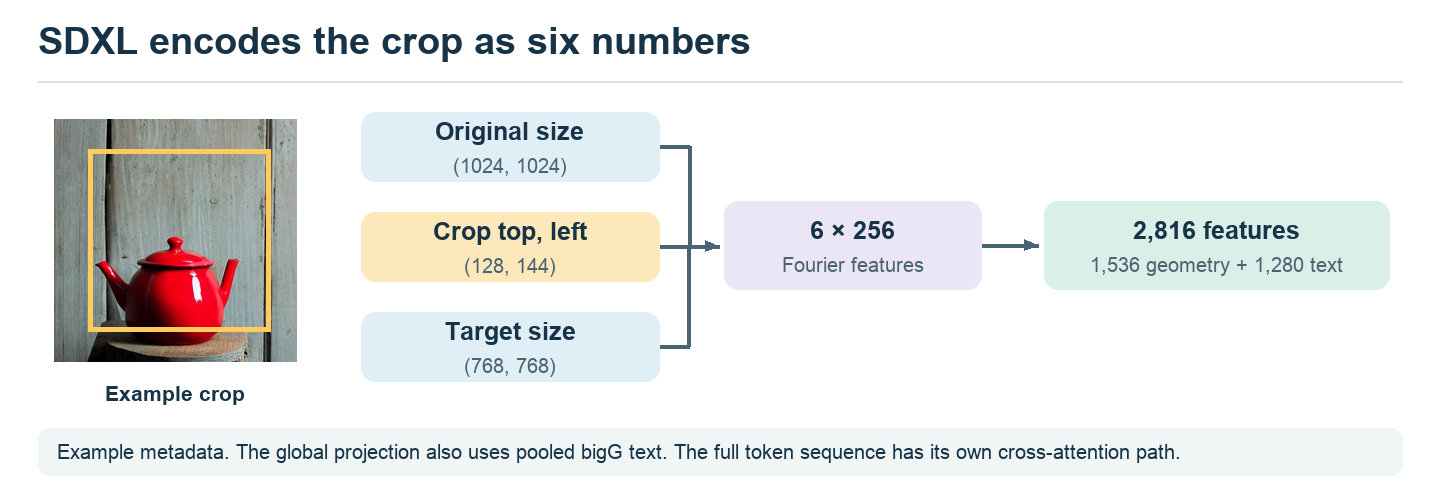

The box marks an illustrative 768 × 768 crop of a 1024 × 1024 canvas. Each scalar receives 256 features. Concatenating the six embeddings with the 1,280 pooled text features gives the global projection its 2,816 inputs. The crop metadata can influence the generated composition. [SDXL base configuration](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0/blob/main/unet/config.json)

### SD 2.1 · which denoising target?

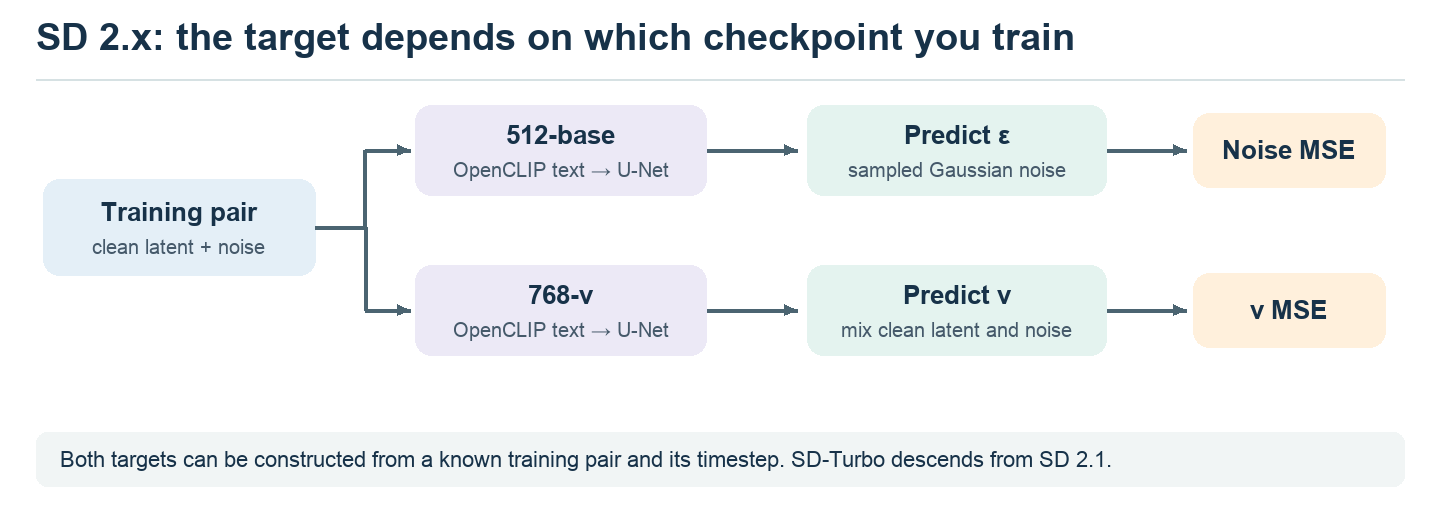

The 512-base model learns sampled noise. In the 768-v branch, with $z_t=\alpha_t z_0+\sigma_t\epsilon$ and $\alpha_t^2+\sigma_t^2=1$, supervise $v=\alpha_t\epsilon-\sigma_t z_0$ by squared error. The model uses frozen OpenCLIP ViT-H text features. The release describes LAION-derived, filtered training stages; counts of unique pairs depend on the stage and are unspecified in the cited checkpoint descriptions. This diffusion $v$ uses different coefficients from the straight-line flow target used later by SD3.

[Stability AI model specifications](https://github.com/Stability-AI/ModelSpec) · [LCM paper, §5.1, SD 2.1 teacher configurations](https://arxiv.org/html/2310.04378)

### SDXL base · the same loss at three image scales

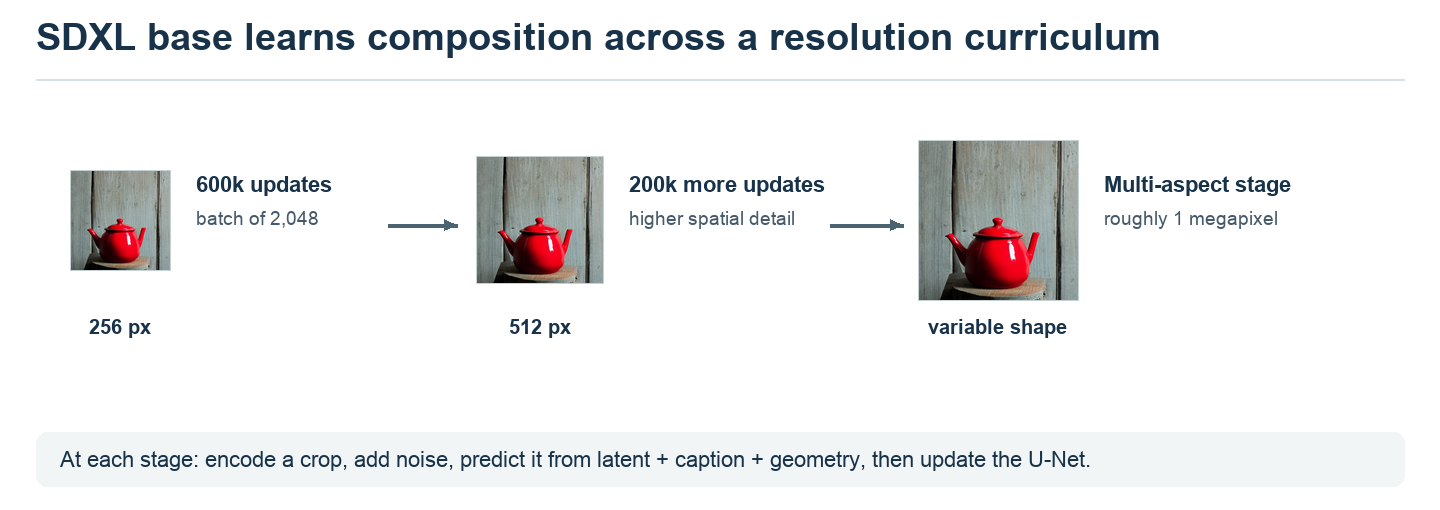

The internal training set provides image–caption pairs. In each batch, encode the crop to a latent, draw the noise and time, and feed size/crop information with the text. Train the base U-Net to recover the sampled noise with a denoising squared error. The frozen autoencoder and text encoders supply inputs.

**How much?** Stage one alone processes $600{,}000\times2{,}048=1{,}228{,}800{,}000$ **example presentations**. Repeated draws count each time. A further 200,000 optimizer updates use 512² crops. The final stage uses several aspect ratios at about one megapixel. The authors do not give a distinct-pair count for the internal corpus.

[Podell et al., §§2.2–2.5](https://arxiv.org/html/2307.01952) · [SDXL base prediction configuration](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0/blob/main/scheduler/scheduler_config.json)

### How does SDXL form a rectangular batch?

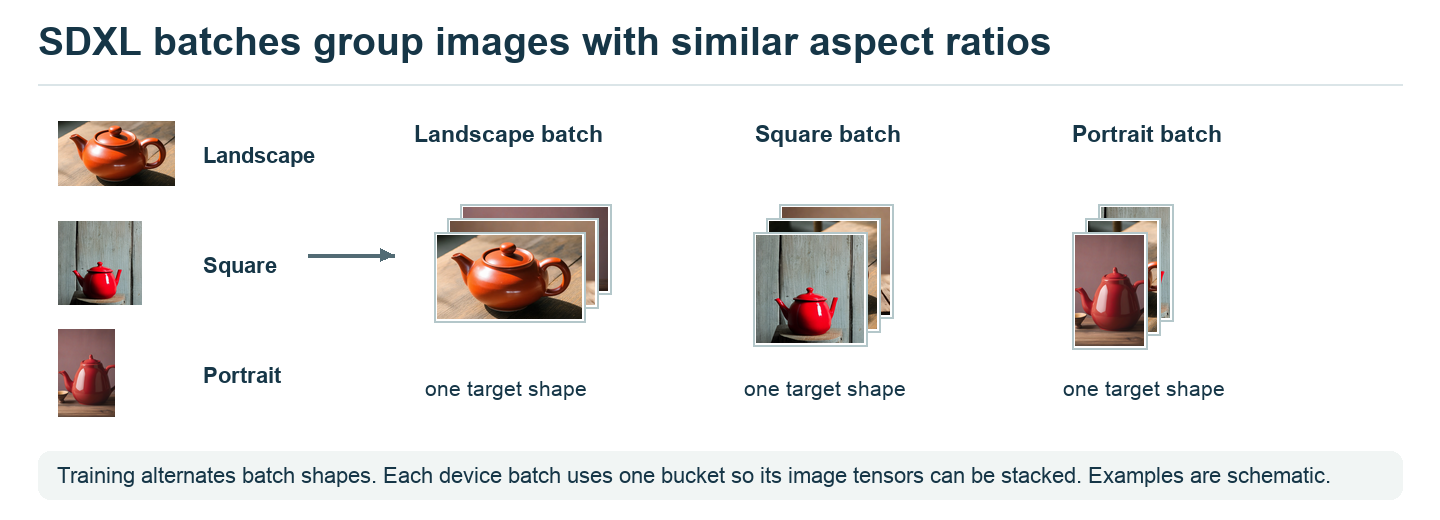

Consider two images with the same area, one tall and one wide. SDXL groups items by aspect ratio and samples a target shape for a training step. Resize and crop examples to the matching shape, retain each example’s size and crop metadata, then stack the batch. This lets one U-Net train with multiple aspect ratios. The pictures illustrate the grouping rule. [SDXL, §2.3 and Appendix I](https://arxiv.org/html/2307.01952)

### SDXL base and refiner · what travels between them?

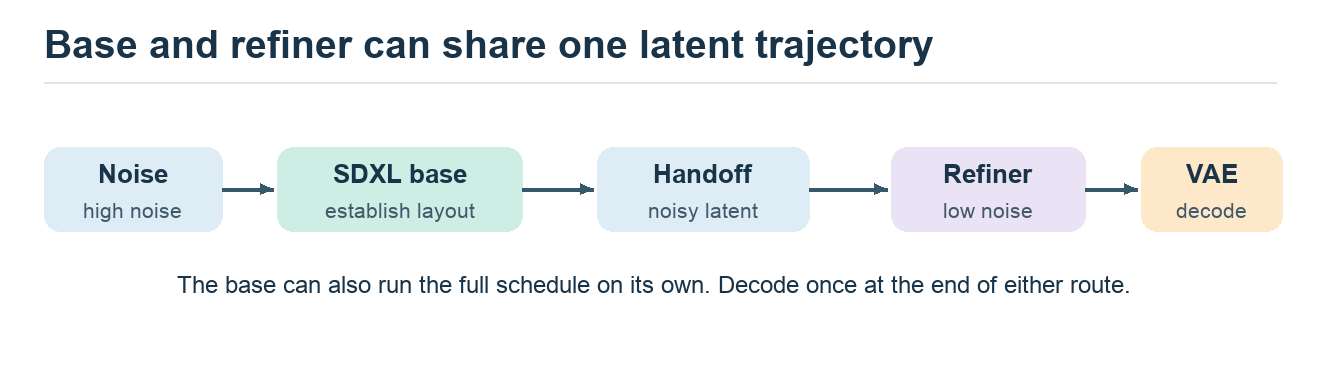

The base can finish a 1024-class image by itself. In the optional two-expert pipeline, stop the base while the image is still noisy. Pass that intermediate **latent** to a separately trained refiner specialized for low noise. It can update the glaze and fine edges. The VAE decodes the finished latent once. This differs from the change of spatial resolution between stages in Imagen.

For an illustrative 80% handoff, both pipelines agree on the time grid: the base stops at the boundary, and the refiner resumes there. The split is a sampling choice. SDXL-Turbo in our lab uses its own distilled model and schedule.

[SDXL base and refiner usage](https://huggingface.co/stabilityai/stable-diffusion-xl-base-1.0)

### Training the low-noise expert

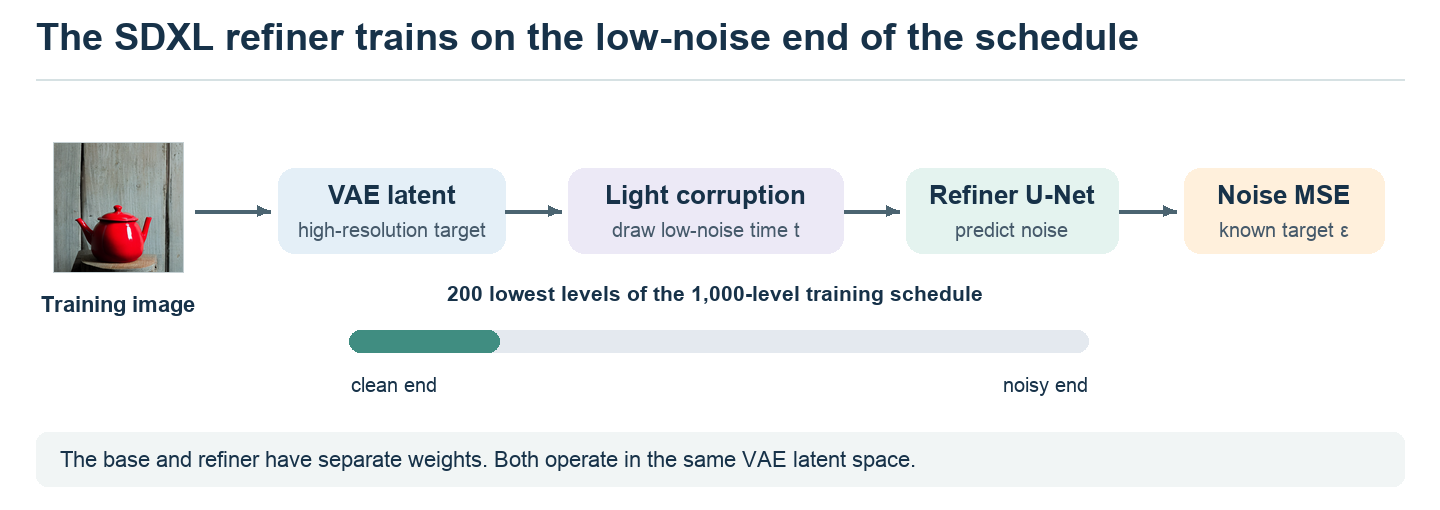

To train the refiner, take a high-quality, high-resolution image, encode it in the shared latent space and corrupt it at a low noise level. The refiner predicts that perturbation with a noise-regression objective. This teaches local corrections around nearly finished images. The paper specializes it on the **lowest 200 of 1,000 discrete noise levels**. The public description gives the training regime without a count of unique refiner examples.

**Classroom check.** Those 200 levels specify where training examples come from on the noise schedule. The 80% handoff in the earlier sampling example specifies when to switch networks at generation time.

[SDXL, §2.5, refinement stage](https://arxiv.org/html/2307.01952) · [Refiner prediction configuration](https://huggingface.co/stabilityai/stable-diffusion-xl-refiner-1.0/blob/main/scheduler/scheduler_config.json)

## SD3 and SD3.5 · build the conditioning sequence

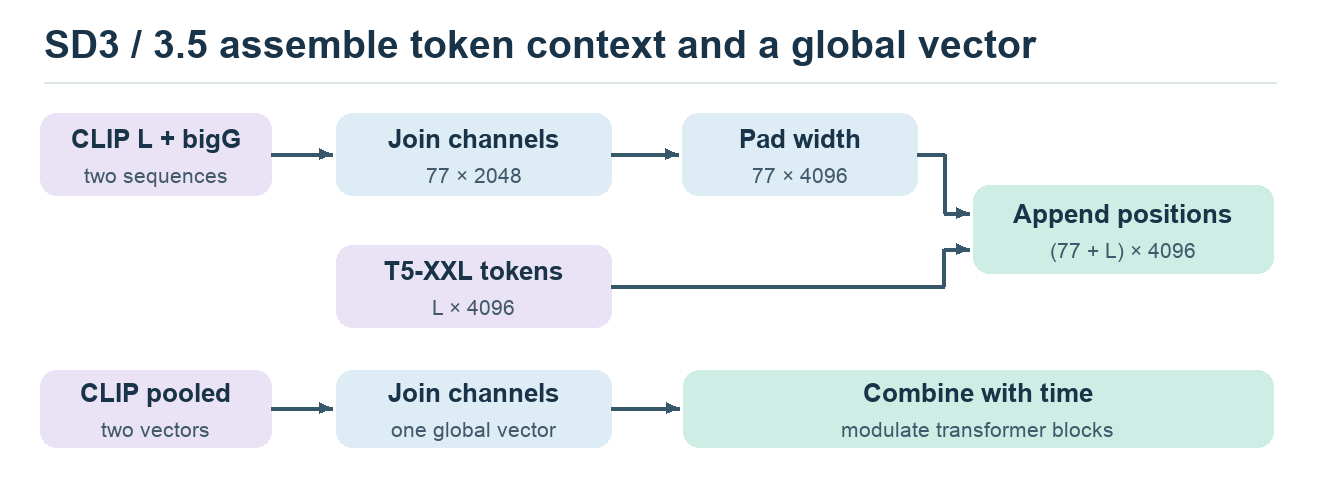

Both families use two CLIP text encoders and, in the full pipeline, T5-XXL. The CLIP token features are joined across channels and padded to the T5 width. T5 positions are then appended along the **sequence** dimension. The CLIP pooled vectors follow a second path and condition the transformer together with time.

For a batch of one and a T5 sequence padded to length $L=256$, the assembled context has shape $(1,333,4096)$ before its learned projection. The pooled condition has shape $(1,2048)$. The two CLIP branches share a position axis in this assembly; T5 contributes its own positions. Ask students to predict which axis changes if $L$ doubles.

[Diffusers SD3 prompt assembly, pinned implementation](https://github.com/huggingface/diffusers/blob/v0.35.2/src/diffusers/pipelines/stable_diffusion_3/pipeline_stable_diffusion_3.py)

### Why does SD3 also read text with T5?

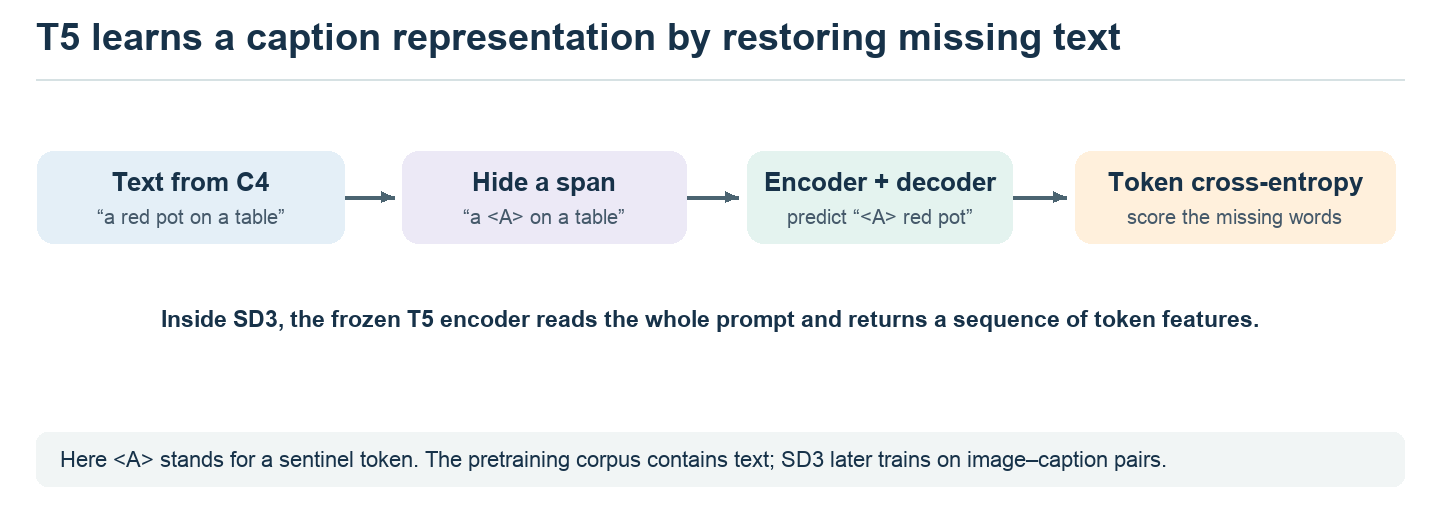

During T5 pretraining, replace spans of words with sentinel tokens. The decoder predicts the missing spans given the encoder state. The training loss is token cross-entropy on that target sequence. T5 v1.1 was pretrained on the C4 **text** corpus. During SD3 training the T5 encoder is frozen and its hidden states form one part of the caption condition. Gradients from velocity regression train the diffusion transformer.

**Compare the encoders.** CLIP learned from matching images to captions. T5 learned from recovering missing text. A single SD3 training example can reuse both representations of the same prompt.

[T5 pretraining objective](https://arxiv.org/abs/1910.10683) · [T5 v1.1 XXL data](https://huggingface.co/google/t5-v1_1-xxl) · [SD3 conditioning, Appendix B.2](https://arxiv.org/html/2403.03206)

### Before SD3 training: identify near duplicates

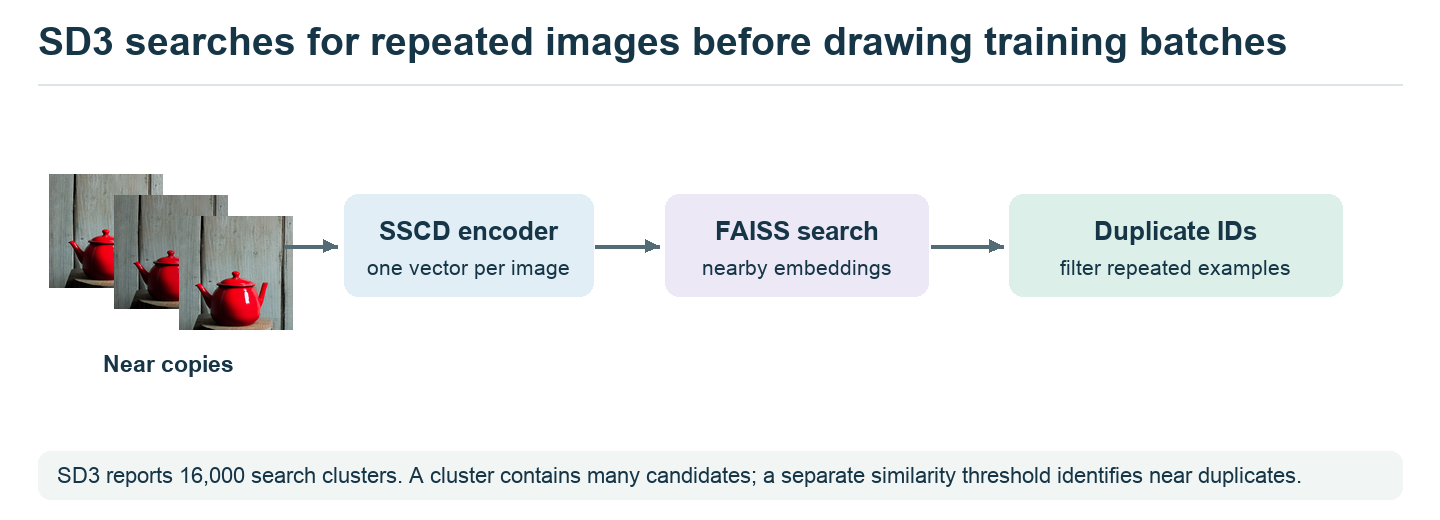

A slight crop or brightness change can leave essentially the same training image. The SD3 authors embed images with SSCD, group embeddings into 16,000 search clusters, and compare candidates within a cluster. A similarity cutoff yields duplicate IDs for filtering. Read **16,000** as the number of search clusters. [SD3, Appendix E.2, Algorithm 1](https://arxiv.org/html/2403.03206)

### One photo can carry two teaching signals in its text

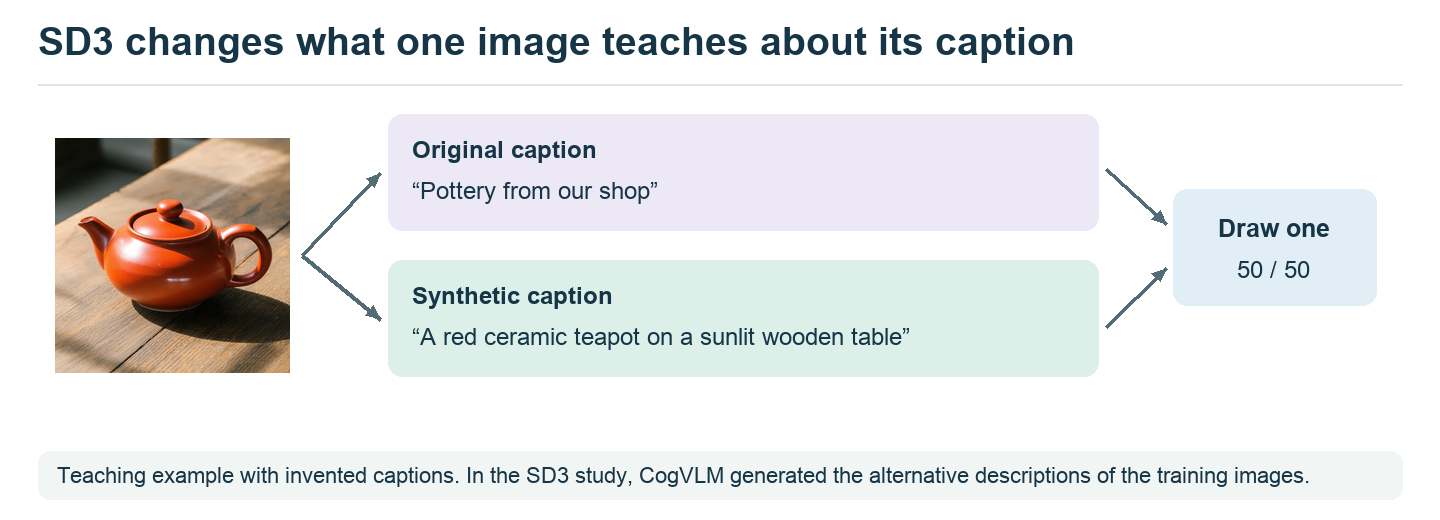

Hold the image fixed. In the SD3 paper, CogVLM produces a second description of training images. Sampling between original and synthetic text changes the conditioning features attached to a given visual target. The example captions above were written for this seminar. A synthetic **caption** can describe a real training image. [SD3, §5.2.2](https://arxiv.org/html/2403.03206)

In [ ]:
# Shape-only exercise: dummy encoder outputs, independent of any checkpoint.
import torch
import torch.nn.functional as F

clip_l = torch.zeros(1, 77, 768)
clip_g = torch.zeros(1, 77, 1280)
clip_tokens = torch.cat([clip_l, clip_g], dim=-1)
for t5_length in (64, 256):
    t5_tokens = torch.zeros(1, t5_length, 4096)
    padded = F.pad(clip_tokens, (0, t5_tokens.size(-1) - clip_tokens.size(-1)))
    combined = torch.cat([padded, t5_tokens], dim=1)
    print(f"T5 length {t5_length:3d} | SDXL {tuple(clip_tokens.shape)} | SD3 {tuple(combined.shape)}")

T5 length  64 | SDXL (1, 77, 2048) | SD3 (1, 141, 4096)
T5 length 256 | SDXL (1, 77, 2048) | SD3 (1, 333, 4096)


### MMDiT · what happens to the word “red” inside the denoiser?

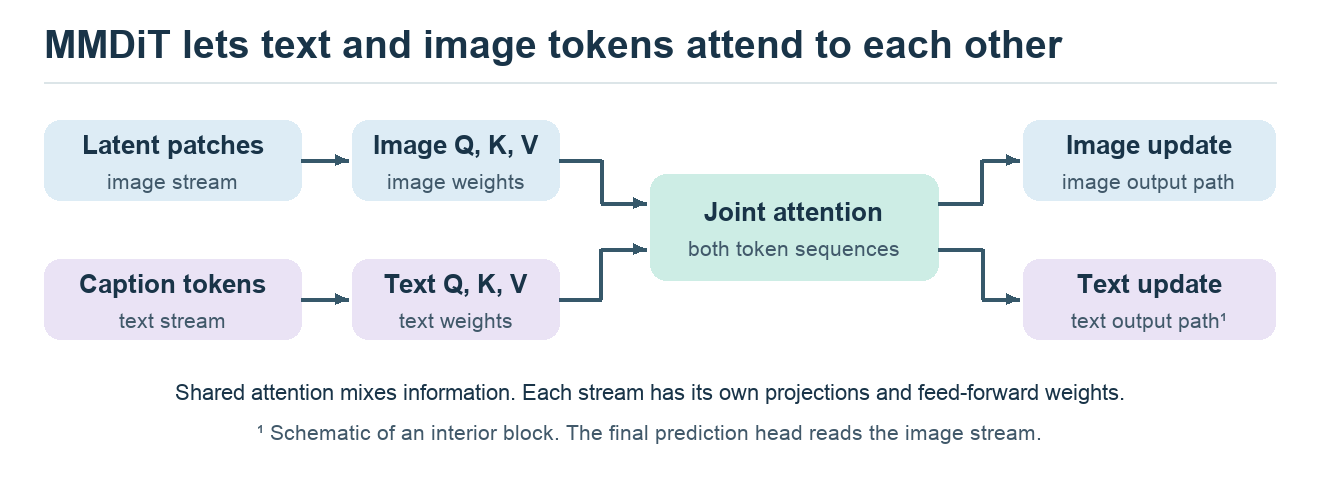

Patchify the noisy spatial latent to form image tokens. Project the assembled caption into text tokens of the block's width. The two streams use separate learned projections to make queries, keys and values. In a typical interior block, each modality can attend to positions from **both** streams:

$$Q=[Q_{\rm img};Q_{\rm txt}],\quad K=[K_{\rm img};K_{\rm txt}],\quad V=[V_{\rm img};V_{\rm txt}],\qquad
O=\operatorname{softmax}(QK^\top/\sqrt{d})V.$$

Split $O$ back into image and text positions and apply the respective output paths. An image patch can read the token for red; a text token can also read the current image patches. In SDXL cross-attention the U-Net reads an externally encoded text sequence. SD3's final image head converts patch predictions back into a spatial velocity field.

**SD3 → SD3.5.** SD3 introduced the rectified-flow MMDiT. The 3.5 family retains that foundation and adds refinements such as QK normalization. Medium (2.5B) uses the MMDiT-X variant; Large (8.1B) and its four-step distilled Large Turbo are separate checkpoints. The names Medium and Turbo answer different questions: model capacity and sampling budget.

[Esser et al., SD3](https://arxiv.org/abs/2403.03206) · [Stability AI, SD3.5 variants](https://stability.ai/news-updates/introducing-stable-diffusion-3-5)

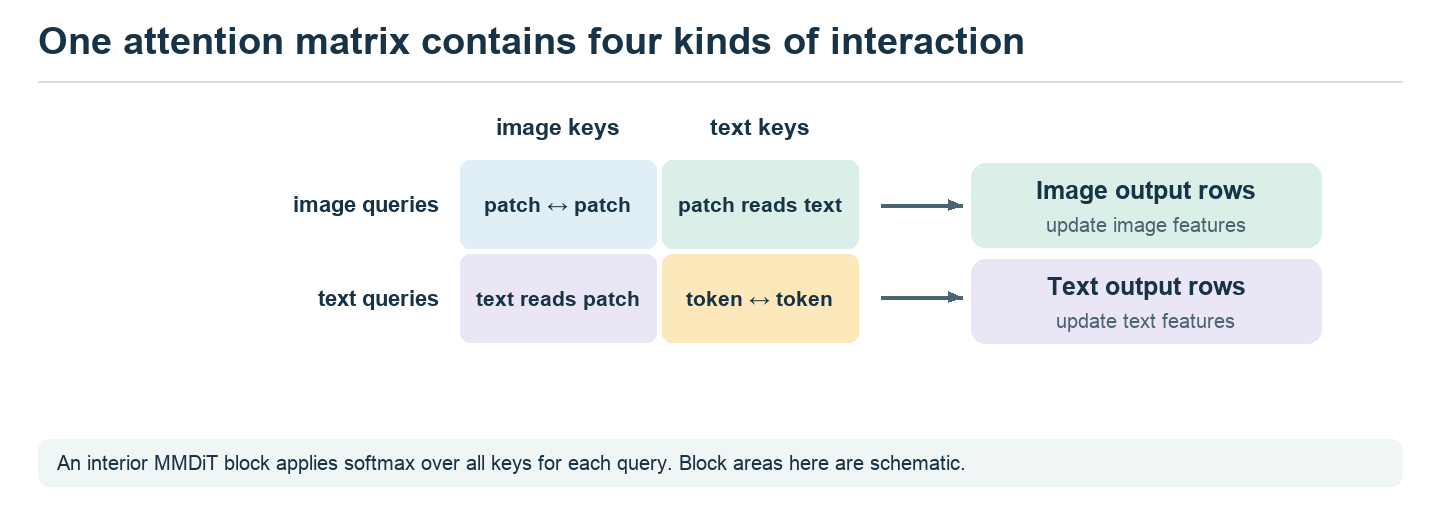

Pick a text query and trace its row to the image-key columns. That lower-left block lets the caption representation read the current image patches. The two upper blocks supply the image output rows. [SD3 architecture](https://arxiv.org/html/2403.03206)

### Follow the same word across the three architectures

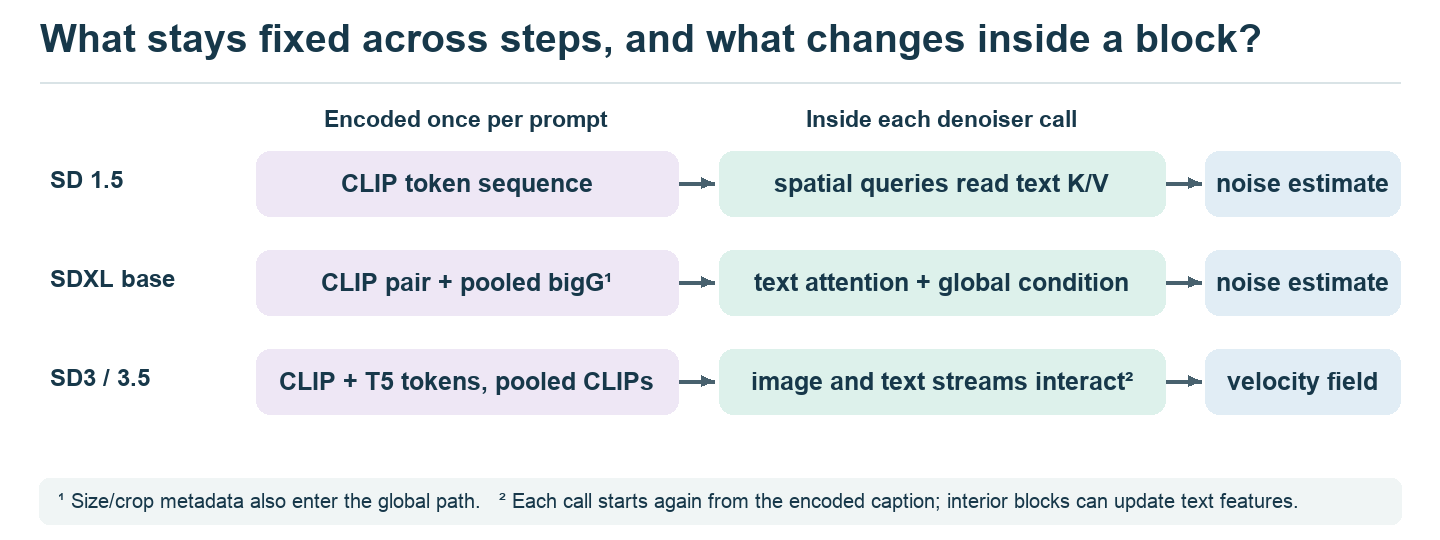

In **SDXL base**, changing *red* can affect both CLIP token sequences and the pooled bigG vector. The first route changes the keys and values read by the U-Net. The second changes a global conditioning vector combined with size/crop and time. In **SDXL-Turbo** the prompt still follows the XL conditioning routes when the extra CFG branch is disabled.

In **SD3/3.5**, the CLIP and T5 encoders can be run once for the prompt. On every denoising call the model projects their context and the noisy image patches into the MMDiT block stack. In an interior block a text query can read image keys and values, so its updated text row can carry information about this particular noisy image into the **next block of the same call**. At the next sampling time the latent has changed and the model starts from the encoded prompt again. The image head returns the flow prediction for the scheduler. [SDXL](https://arxiv.org/html/2307.01952) · [SD3](https://arxiv.org/html/2403.03206) · [SD3 implementation](https://github.com/huggingface/diffusers/blob/v0.35.2/src/diffusers/models/transformers/transformer_sd3.py)

### SD3.5 Medium, Large and Large Turbo · what was released?

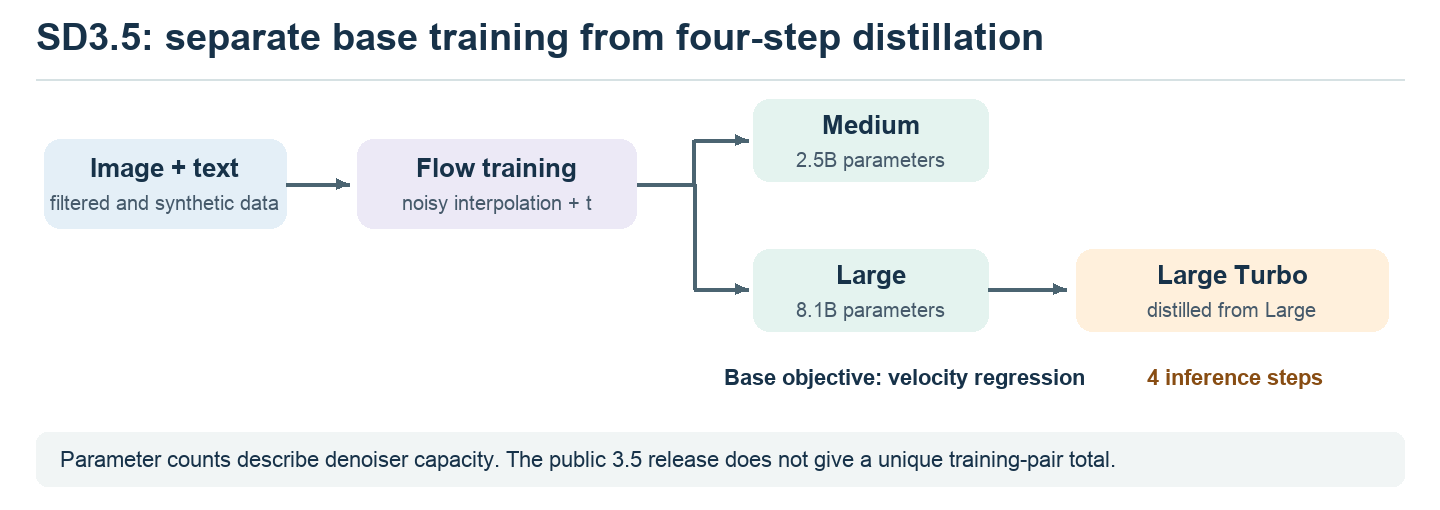

Medium and Large use a multimodal transformer to estimate a latent flow field. Training pairs provide clean latents and captions; sampled noise provides the other endpoint. The **family-level** objective is velocity regression, expanded in the next section. Stability AI describes a mixture including synthetic and filtered publicly available data. The release cards give architecture sizes and training approach but no exact unique-pair count or full loss-weight schedule for these checkpoints.

Large Turbo uses **adversarial diffusion distillation** from Large. Its four steps refer to generation after distillation. The release does not report a complete checkpoint-specific balance of teacher and adversarial loss terms.

[Stability AI release](https://stability.ai/news-updates/introducing-stable-diffusion-3-5) · [SD3.5 Large data](https://huggingface.co/stabilityai/stable-diffusion-3.5-large) · [Large Turbo model card](https://huggingface.co/stabilityai/stable-diffusion-3.5-large-turbo)

### The published SD3.5 Large recipe also varies caption length

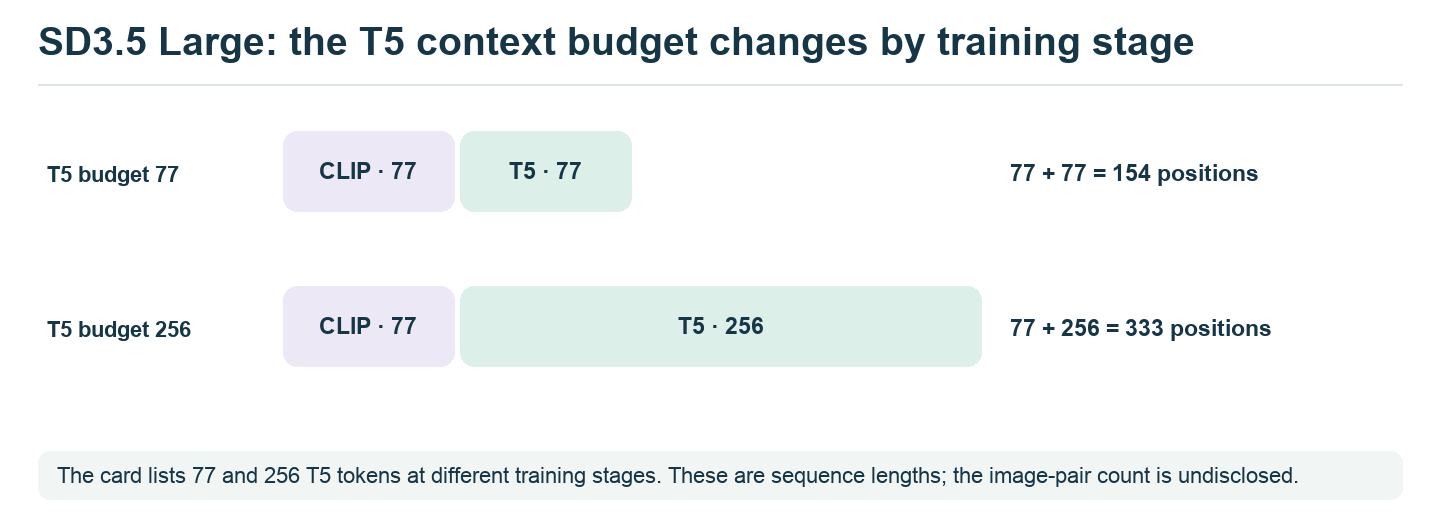

The SD3.5 Large card names filtered public data and synthetic data, and reports T5 context lengths of **77 and 256** across stages. The corresponding assembled sequence lengths shown above follow the prompt assembly in this notebook. The card does not give the fraction of synthetic examples, the number of updates per length or a unique image count. [SD3.5 Large, implementation and training data](https://huggingface.co/stabilityai/stable-diffusion-3.5-large) · [Diffusers prompt assembly](https://github.com/huggingface/diffusers/blob/v0.35.2/src/diffusers/pipelines/stable_diffusion_3/pipeline_stable_diffusion_3.py)

### Rectified flow · what does the network predict?

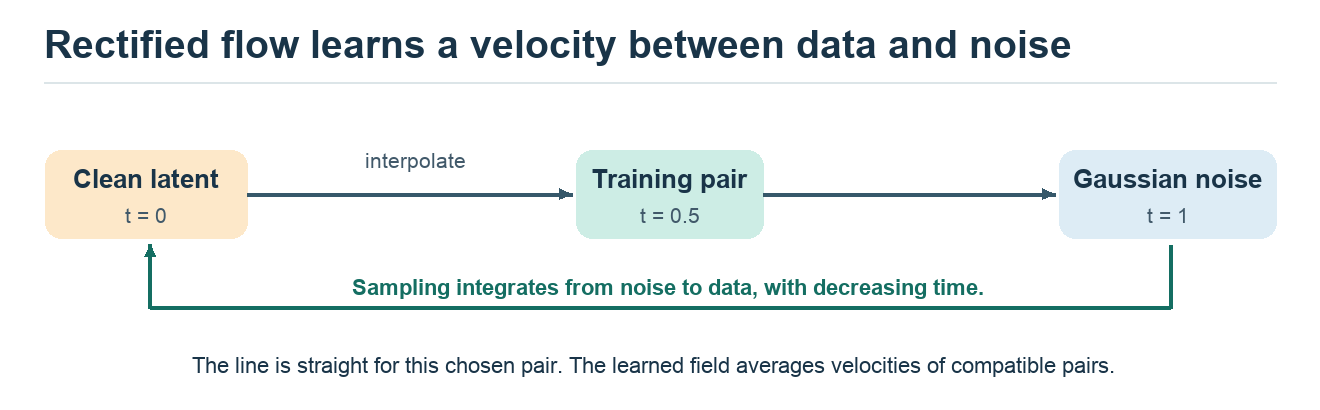

Use the **data-to-noise** convention $z_t=(1-t)z_0+t\epsilon$, where $t=0$ is a clean latent and $t=1$ is noise. On this sampled training pair the derivative is $\epsilon-z_0$. The network minimizes squared error to this target, given $z_t$, $t$ and the caption. At sampling time we integrate backward from noise. For a small positive $\delta$, an Euler update is $z_{t-\delta}=z_t-\delta v_\theta(z_t,t,c)$.

**On the board.** Take $z_0=2$, $\epsilon=6$. The midpoint is 4 and the training target is +4. Starting from 6, a reverse step of 0.25 gives 5. The minus sign comes from moving toward smaller $t$. This single-pair calculation illustrates the sign. The learned field averages over compatible pairs, and real sampling trajectories can curve.

[Esser et al., rectified flow](https://arxiv.org/abs/2403.03206)

### SD3 · who supplies the velocity label?

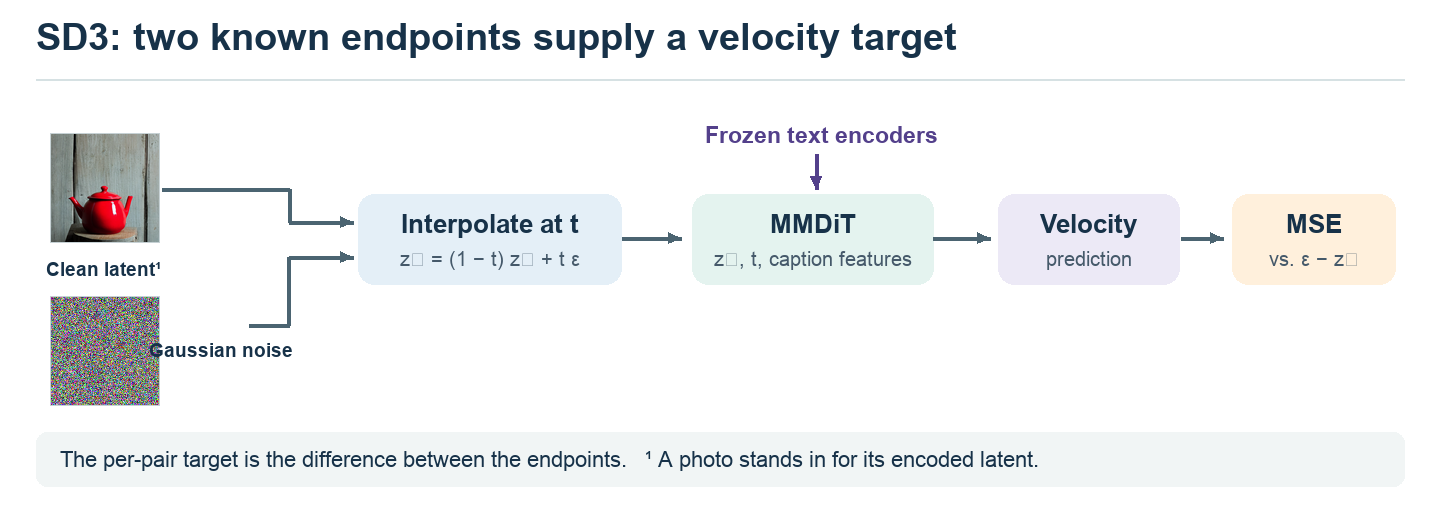

For the time convention above, take $t$ from the training time distribution and minimize
$$\mathcal L_{\rm flow}=\mathbb E_{z_0,c,\epsilon,t}\left[\|v_\theta(z_t,t,c)-(\epsilon-z_0)\|_2^2\right].$$
Compare to SD 1.5: the target now uses **both endpoints**. The SD3 paper studies timestep sampling, including logit-normal sampling that puts more examples at intermediate noise levels.

**Caption data.** The authors compare two equal-size experimental models for **250k updates**: original captions versus a **50/50 mixture of original and synthetic captions**. They retain the mix for subsequent SD3 experiments. Here 50% describes caption choice, and 250k describes this controlled comparison. Neither number establishes the size of the SD3.5 training set.

[Esser et al., §§3 and 5, caption ablation in Table 4](https://arxiv.org/html/2403.03206)

### Sampling a time changes which errors the model sees more often

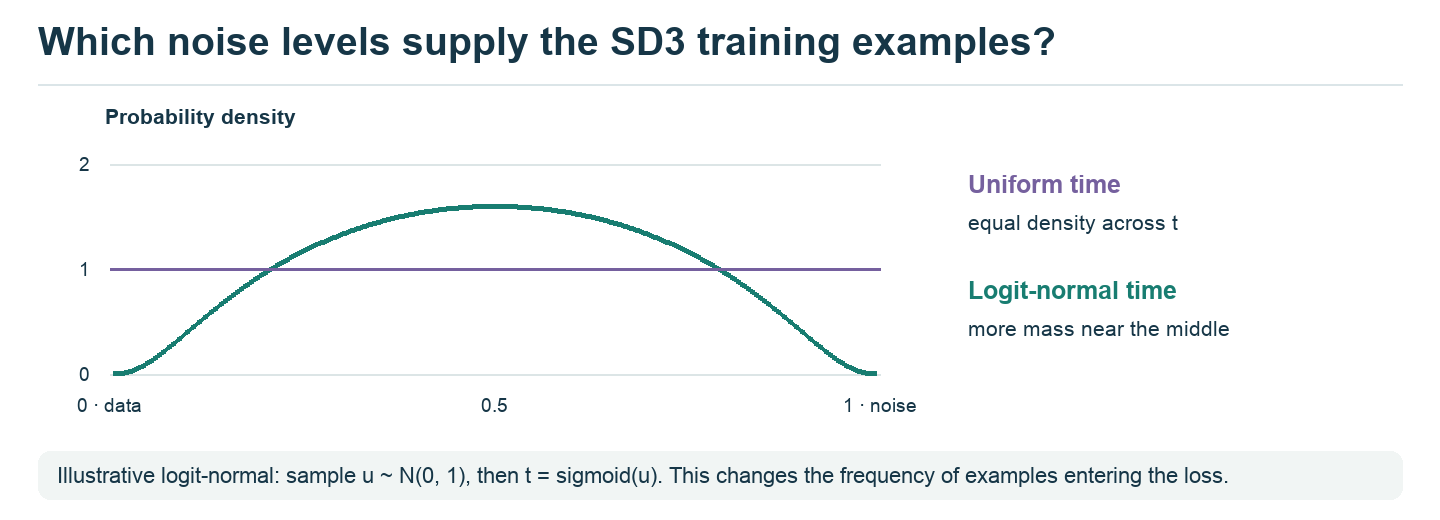

The example uses a standard normal draw followed by a sigmoid. More training draws land near the midpoint. Each sampled pair still uses its endpoint difference as the velocity label. **Ask:** would changing the distribution of time change the target for the same endpoints, or the frequency with which particular noisy inputs contribute to the loss? [SD3, logit-normal timestep sampling](https://arxiv.org/html/2403.03206)

### Test the caption recipe with a controlled comparison

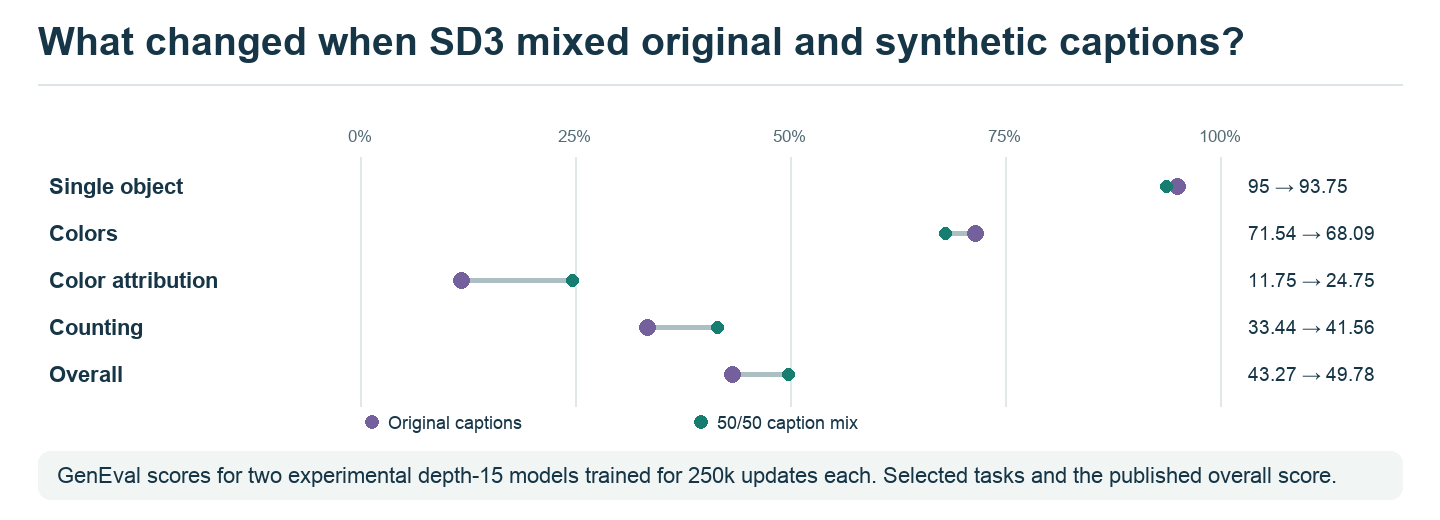

Both experimental SD3 models had depth 15 and received 250k updates. The mixed-caption run gained **13.00 percentage points on color attribution** and lost **3.45 points on the Colors task**. The overall score rose **6.51 points**. These scores belong to the caption ablation; they do not measure the four released checkpoints in the opening gallery. [SD3, Table 4](https://arxiv.org/html/2403.03206)

## Turbo · where did the other denoising steps go?

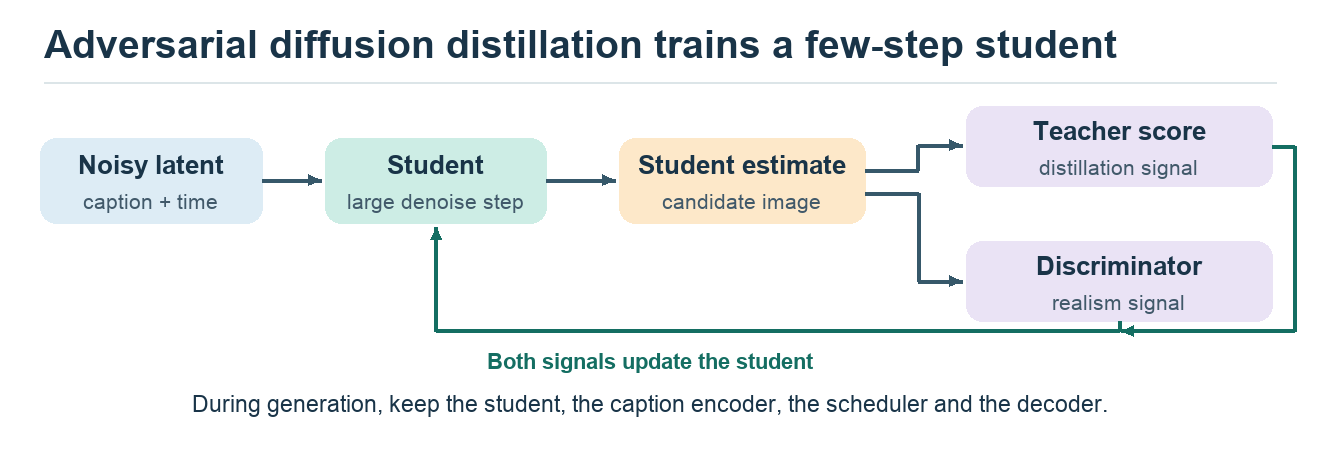

Setting a base sampler to one step gives its network one attempt to cover the whole path. Distillation changes the **weights** so a student learns useful large jumps. For SD-Turbo and SDXL-Turbo, adversarial diffusion distillation (ADD) combines a teacher-derived score signal with a discriminator trained to recognize real images. During generation, only the student needs to denoise.

| Checkpoint | Parent and training | Inference recipe |
|---|---|---|
| SD-Turbo | SD 2.1, ADD | 1–4 steps, typically 512², CFG disabled |
| SDXL-Turbo | SDXL, ADD | 1–4 steps, typically 512², CFG disabled |
| SD3.5 Large Turbo | Distilled SD3.5 Large, flow transformer | Four steps in the published recipe, CFG disabled |
| SDXL-Lightning | SDXL base, progressive adversarial distillation | Pick weights trained for the requested step count (1, 2, 4 or 8) |
| LCM / LCM-LoRA | Learn consistent endpoint predictions along a guided diffusion trajectory | Use the corresponding consistency scheduler and a few steps |

Here `guidance_scale=0.0` switches off the **extra CFG branch** in the Diffusers Turbo pipelines. They still encode the prompt and call the denoiser with the requested caption. The two-branch algebra in our hand-written SD 1.5 sampler uses a different convention at zero.

[ADD paper](https://arxiv.org/abs/2311.17042) · [SD-Turbo](https://huggingface.co/stabilityai/sd-turbo) · [SDXL-Turbo](https://huggingface.co/stabilityai/sdxl-turbo) · [3.5 Large Turbo](https://huggingface.co/stabilityai/stable-diffusion-3.5-large-turbo) · [Lightning](https://huggingface.co/ByteDance/SDXL-Lightning) · [LCM](https://arxiv.org/abs/2310.04378)

### SD-Turbo and SDXL-Turbo · two losses for one student

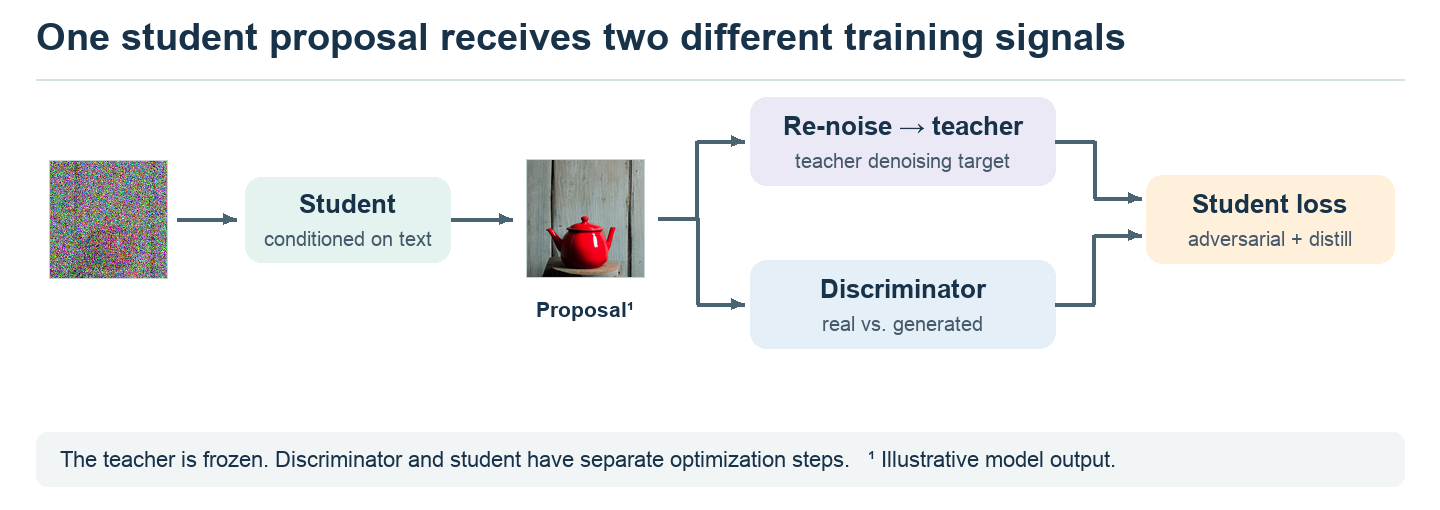

Draw a real image–caption pair, a noise level and a perturbation. A student initialized from a pretrained denoiser proposes a clean sample. Re-noise its proposal, let the frozen teacher denoise it, and use the teacher output as a detached target. In parallel, train a discriminator to separate real images from student outputs. During the student update, its adversarial term rewards convincing outputs:
$$\mathcal L_{\rm student}=\mathcal L_{\rm adv}^{G}+\lambda\,\mathcal L_{\rm distill}.$$
The gradients from both terms change the student. SD-Turbo builds on SD 2.1 and SDXL-Turbo on SDXL. The ADD paper's **Table 1 ablations** use 4,000 iterations and a batch of 128; the exact unique-pair counts and full optimization budgets of the released Turbo checkpoints are unspecified. The teacher and discriminator are training-time components.

[Sauer et al., ADD, §§3–4 and Table 1](https://arxiv.org/html/2311.17042) · [SD-Turbo](https://huggingface.co/stabilityai/sd-turbo) · [SDXL-Turbo](https://huggingface.co/stabilityai/sdxl-turbo)

### Lightning and LCM · what is the student asked to match?

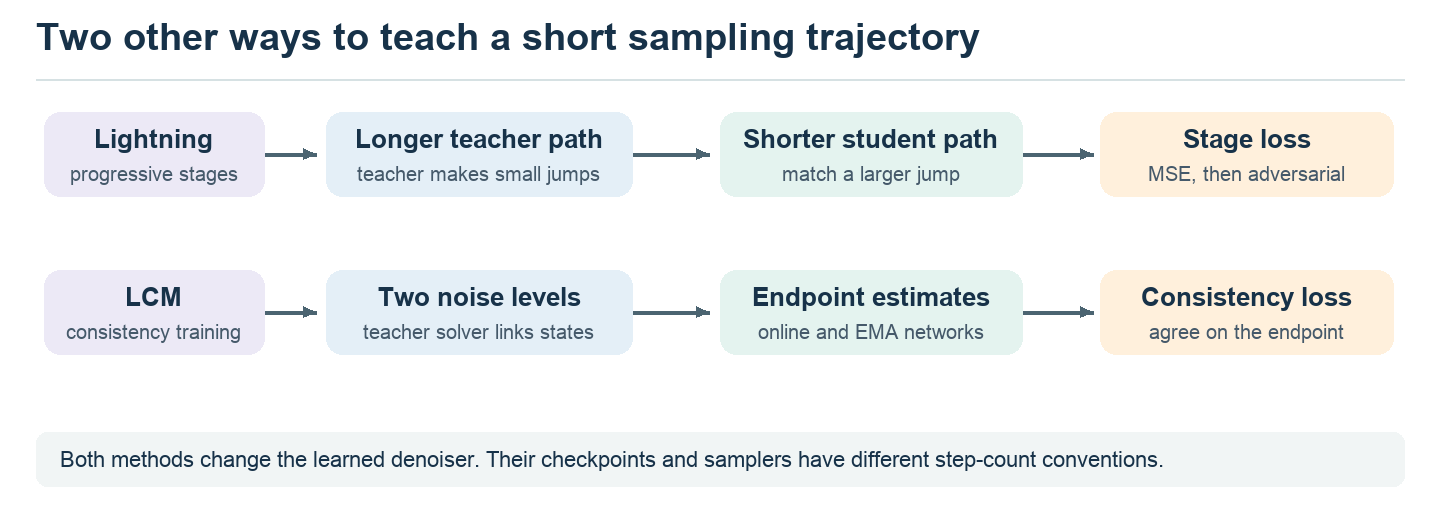

**SDXL-Lightning.** The first stage distills a 128-step schedule into 32 steps using MSE. Later stages progressively shorten the trajectory using adversarial training. The paper describes filtered LAION and COYO images, a 1024-pixel training crop and a global batch of 512 across 64 A100s. It gives filtering criteria rather than a final distinct-image count. The released checkpoints correspond to particular step counts.

**LCM.** Pick two noise levels, use the teacher solver to connect their states, then train the online model's endpoint estimate to agree with a detached target-network estimate from the other state. The target is an exponential moving average of the online model. The LCM paper identifies **12M LAION-Aesthetics-6+ pairs** for its 512² experiments and **650k LAION-Aesthetics-6.5+ pairs** for 768². Those are reported pool sizes for the paper's LCM experiments. LCM-LoRA applies consistency distillation through low-rank updates; its individual releases have their own training recipes.

[Lin et al., SDXL-Lightning](https://arxiv.org/html/2402.13929) · [Luo et al., LCM, Algorithm 1 and §5.1](https://arxiv.org/html/2310.04378) · [LCM-LoRA](https://arxiv.org/abs/2311.05556)

### Distillation: trace each gradient to its recipient

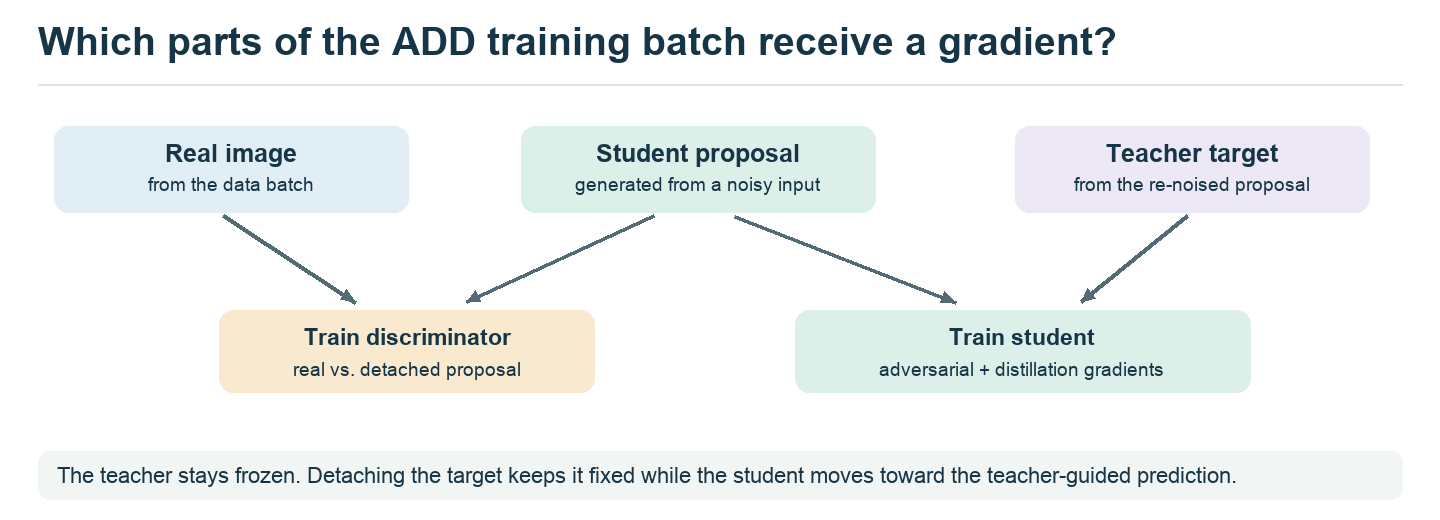

For the discriminator update, classify real samples and detached student proposals. For the student update, evaluate the discriminator on the differentiable proposal and add a teacher-derived correction computed after re-noising that proposal. The teacher target is held fixed for differentiation. This diagrams the published ADD training method used to explain SD-Turbo and SDXL-Turbo. [Sauer et al., ADD, §3 and equations 1–4](https://arxiv.org/html/2311.17042)

### Compare one, two and four steps on SDXL-Turbo
Use the same teapot caption, initial latent, resolution and random seed. The checkpoint's Euler ancestral scheduler also consumes step noise; changing the step count changes the time grid. These are three complete samples. Inspect the outline, the two ends of the handle and the shadow. Choose the first step budget you would accept for this seed.

In the saved run, the red body and lid are recognizable after one step. At two steps the right-hand protrusion resembles a second spout. At four steps the right-hand loop closes into a handle. Which of these changes matters more than the surface gloss?

The cell downloads SDXL-Turbo on its first live run. The earlier SD 1.5 models move to CPU during this experiment. A fresh runtime needs the setup, prompt and display helper cells above. [SDXL-Turbo inference recipe](https://huggingface.co/stabilityai/sdxl-turbo)

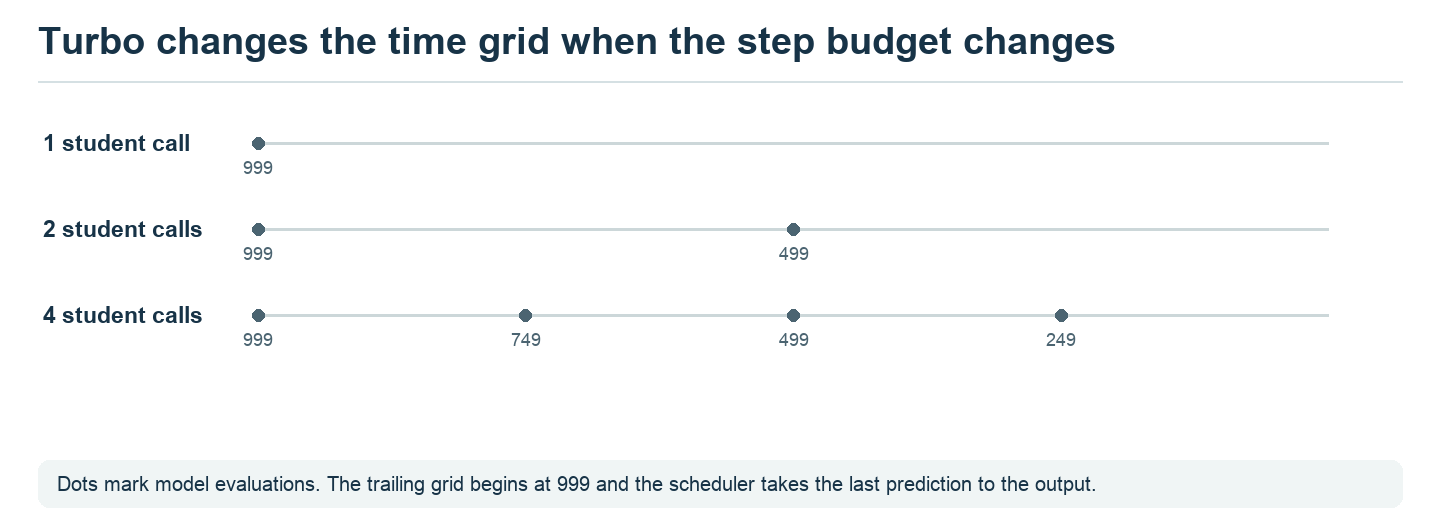

The one-step result is a finished sample. In the four-step run, the first update hands a latent to the model again at time 749. The last update decodes to a finished image after the remaining calls.

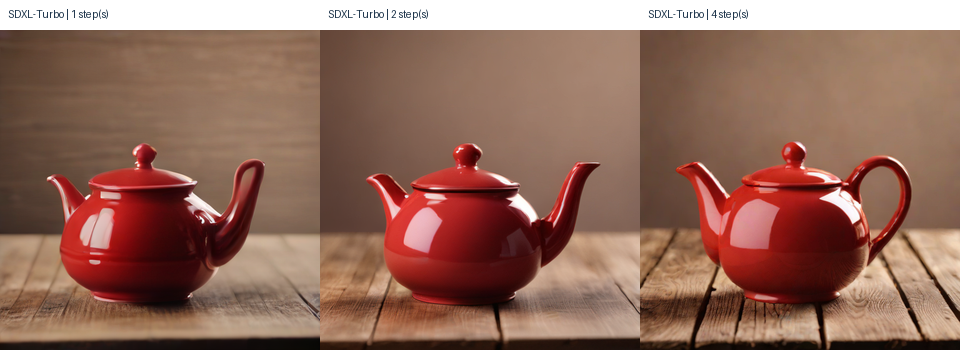

In [ ]:
# Optional live run. Saved results below are available on every runtime.
from diffusers import StableDiffusionXLPipeline
import gc

def compare_turbo():
    # Free accelerator memory used by the earlier SD 1.5 exercise.
    for model in (unet, text_encoder, vae):
        model.to("cpu")
    turbo = None
    try:
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()
        turbo = StableDiffusionXLPipeline.from_pretrained(
            "stabilityai/sdxl-turbo", revision="71153311d3dbb46851df1931d3ca6e939de83304",
            variant="fp16", torch_dtype=dtype, use_safetensors=True, add_watermarker=False,
        )
        if device == "cuda":
            turbo.enable_model_cpu_offload()
        else:
            turbo.to(device)
        generator = torch.Generator("cpu").manual_seed(seed)
        noise = torch.randn((1, 4, 64, 64), generator=generator, dtype=torch.float32)
        panels = []
        for steps in (1, 2, 4):
            image = turbo(
                prompt=prompt, height=512, width=512, num_inference_steps=steps,
                guidance_scale=0.0, latents=noise.to(device, dtype).clone(),
                generator=torch.Generator("cpu").manual_seed(seed + 1),
            ).images[0]
            panels.append((f"SDXL-Turbo | {steps} step(s)", image))
        show_row(panels)
    finally:
        del turbo
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()
        for model in (unet, text_encoder, vae):
            model.to(device)

compare_turbo()

### Choose the model for the request
*“Where does the phrase enter?”* Trace the token route for SDXL, then explain what becomes bidirectional in MMDiT. *“Can the system keep reading my prompt with CFG disabled?”* Find the conditional-only denoiser call in the Turbo recipe. *“Would four steps on SD3.5 Large reproduce Large Turbo?”* Name the change made during training.

Optional SD3.5 Medium run: accept the checkpoint terms on Hugging Face and sign in with read access. For a fresh Colab GPU runtime, first install `%pip -q install diffusers==0.35.2 transformers==4.55.4 accelerate==1.10.1 sentencepiece protobuf`. The full three-encoder pipeline requires sufficient host RAM for CPU offload. The shape exercise above works offline. [SD3.5 Medium model card](https://huggingface.co/stabilityai/stable-diffusion-3.5-medium)

Set the switch below after signing in (use `huggingface_hub.notebook_login()` in a separate cell). Leave it off for the default seminar run.

### Read the training numbers in their own units

| Quantity | Example | What it counts |
|---|---|---|
| Dataset pool | 600M in LAION-Aesthetics V2 at threshold 5 | Published candidate image–text pairs before checkpoint-specific filtering. |
| Optimizer updates | 595k for the last SD 1.5 stage | Times the optimizer changed weights in that stage. |
| Presentations | 600k × 2,048 for the first SDXL stage | Examples processed, including repeats. |
| Caption mix | 50% original / 50% synthetic in the SD3 study | Choice of caption source. |
| Noise levels | Lowest 200 of 1,000 for the SDXL refiner | Range of perturbations seen during specialization. |
| Sampling budget | Four calls for SD3.5 Large Turbo | Denoising steps to generate one sample after training. |

[LAION collection](https://laion.ai/blog/laion-aesthetics/) · [SD 1.5](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5) · [SDXL](https://arxiv.org/html/2307.01952) · [SD3](https://arxiv.org/html/2403.03206) · [SD3.5 release](https://stability.ai/news-updates/introducing-stable-diffusion-3-5)


In [ ]:
RUN_SD35 = False
if RUN_SD35:
    from diffusers import StableDiffusion3Pipeline
    import torch

    pipe = StableDiffusion3Pipeline.from_pretrained(
        "stabilityai/stable-diffusion-3.5-medium", torch_dtype=torch.float16,
    )
    pipe.enable_model_cpu_offload()
    image = pipe("a studio photograph of a red ceramic teapot on a wooden table",
                 num_inference_steps=28, guidance_scale=4.5,
                 generator=torch.Generator("cpu").manual_seed(42)).images[0]
    display(image)